<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAGNN_IntrusionDetection_Chaudhary2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q-AGNN for network intrusion detection: Chaudhary et al. 2026 step by step

**Paper.** Devashish Chaudhary, Sutharshan Rajasegarar, Shiva Raj Pokhrel, *"Q-AGNN: Quantum-Enhanced Attentive Graph Neural Network for Intrusion Detection"*, arXiv:2603.22365 (Deakin University, March 2026). <https://arxiv.org/abs/2603.22365>

**What this notebook does.** It rebuilds the paper's pipeline from public data and plain PyTorch:

1. downloads the full UNSW-NB15 flow records (2.54 million flows) and the Bot-IoT flow records from Hugging Face, groups the flows by `(source IP, destination IP)` pair and builds the **cosine-similarity graph** of the paper (one node per pair, an edge when cosine similarity is at least 0.9);
2. encodes every node with a **4-qubit parameterised quantum circuit** (angle encoding + `EfficientSU2`, Pauli-Z expectation values as the embedding), aggregates the embeddings over **one-hop and two-hop neighbourhoods with node-level attention** (`A` and `A^2`), and classifies the nodes with a small MLP;
3. trains the model with the paper's optimiser settings (Adam, lr 0.01, weight decay 1e-2, up to 1000 epochs, early stopping after 30 epochs without improvement);
4. compares it with seven classical GNNs (GCN, GAT, GraphSAGE, ClusterGCN, GINConv, SuperGAT, TransformerConv, all written in plain PyTorch because `torch_geometric` is not needed), re-runs the paper's ablation study, the t-SNE embedding comparison and the cosine-threshold sensitivity;
5. re-evaluates the trained model under **hardware-calibrated noise** (Qiskit Aer density-matrix simulation with the noise model of an IBM Torino/Fez device) and re-creates the small "hardware-scale" experiment (8 training nodes, 5 test nodes, `SamplerQNN`, 128 shots, 30 epochs) on the noisy simulator;
6. prints the paper's numbers next to this notebook's numbers with a verdict per claim.

**How to run.** Open in Google Colab, choose a **CPU** runtime and press *Runtime -> Run all*. `FAST_MODE = True` (default in the configuration cell) takes roughly 10 minutes on a Colab CPU; `FAST_MODE = False` uses the paper's budget (up to 1000 epochs, 6 random splits, 30 hardware-scale epochs) and takes about an hour. The first run downloads about 130 MB (UNSW-NB15) plus 160 MB (Bot-IoT); the raw files are deleted after the node table has been built. Hugging Face datasets used here are public, so no token is needed; if you use a gated mirror, add your own token as a Colab secret named `HF_TOKEN` (Settings -> Secrets).

**What you get.** Graph statistics next to the paper's Table 2, dataset plots, the executed quantum circuit, Table 4 / Table 6 style results for UNSW-NB15 and Bot-IoT, noisy-simulation results, and an honest verdict on every claim that can be checked. IBM hardware results (paper Section 6.5) **cannot be checked** without your own IBM Quantum access; a cell is provided that runs only if you set `IBM_TOKEN`.

## The paper in one page

* **Problem.** Most deep-learning IDSs treat flows as independent rows. The paper builds a **graph of flows** so that similar flows can exchange information, and adds a **quantum feature encoder** and **attention**.
* **Decision.** Binary node classification: attack (positive) versus normal.
* **Graph.** One node per unique `(srcIP, dstIP)` pair (numeric features averaged over the pair's flows, label = most frequent label of the pair). A bidirectional edge joins two nodes whose feature vectors have cosine similarity `>= 0.9` (Eq. 28). Train, validation and test graphs are separate graphs (Table 2).
* **Preprocessing.** Drop columns with NaN, `LabelEncoder` for categoricals, group by IP pair (mean), Min-Max normalise, PCA to **4 dimensions** (one per qubit), 70/15/15 split.
* **Quantum part.** `RY(x_k)` angle encoding of the four PCA features, an `EfficientSU2` ansatz with linear CNOT entanglement (Eq. 5-7), embedding `z_i = <phi_i| O |phi_i>` of Pauli expectation values (Eq. 8). The circuit is evaluated once per node.
* **Graph part.** `z1 = sum_j A_ij a1_j z_j`, `z2 = sum_j (A^2)_ij a2_j z_j` with node-level attention weights normalised over the graph, fused as `h = sigma(z + z1 + z2)` (Eq. 9-12), then `y = MLP(h)` (Eq. 13). This is a second-order polynomial graph filter.
* **Training.** Adam, lr 0.01, weight decay 1e-2, max 1000 epochs, early stopping patience 30 on validation loss, BCE with logits, threshold 0.5. Noiseless runs use `StatevectorEstimator`; noisy runs use the noise model of an IBM device in `AerSimulator` (density matrix) with `BackendEstimatorV2`, precision 0.03.
* **Data.** Four datasets: Bot-IoT (5% subset, 10 best features), UNSW-NB15, NF-BoT-IoT, NF-UNSW-NB15. **This notebook uses the first two** (see the table below for why).
* **Claims checked here.** Table 2 (graph sizes), Table 4 (Q-AGNN versus seven GNNs, noiseless), Table 5 (noisy simulation), Table 6 (ablations), Table 3 (cosine-threshold sensitivity, paper: NF-UNSW-NB15), Fig. 3 (t-SNE of MLP vs PQC embeddings), Fig. 4 (loss curves), Fig. 5 (hardware-scale loss curves, simulator part only).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| UNSW-NB15 data | full dataset, grouped by IP pair; 311 nodes (217/47/47 in Table 2) | full 2,540,047 flows (HF `research-simulation26/unsw-nb15-parquet`, file `raw_data.parquet`); grouping gives **exactly 311 nodes**, same as Table 2 |
| Bot-IoT data | author-provided 5% subset, 10 best features, 156 nodes | HF `praveet/Bot-IOT_LLM` (`Final.csv`, 179,321 flows stored as text, parsed here): **137 IP pairs**, only DDoS / DoS / normal categories, 13 attack nodes (Table 2: 156). **Substitution**, the original 5% CSVs with IP columns are not on Hugging Face. The 10 features are the Bot-IoT paper's 10 best (`seq, stddev, N_IN_Conn_P_SrcIP, min, state_number, mean, N_IN_Conn_P_DstIP, drate, srate, max`) |
| NF-BoT-IoT, NF-UNSW-NB15 | used | **not used**: the only public copy is behind the University of Queensland data-manager web app (no direct file URL, no mirror on Hugging Face). Claims about these two datasets are "cannot be checked" |
| NaN columns | removed | removed (none left in the Hugging Face copy of UNSW-NB15) |
| Columns used | not listed | all numeric columns except IPs, ports, timestamps, labels; `proto`, `state`, `service` label-encoded `# CHOICE:` |
| Min-Max / PCA fitting | before the split (implied) | **fitted on the training nodes only**, then applied to validation and test nodes (no leakage) `# CHOICE:` |
| Split | 70/15/15 | stratified random split of the nodes, seed-dependent `# CHOICE:` |
| Graph per split | train / val / test graphs with own edge counts | same: each split gets its own graph built only from its own nodes |
| Cosine similarity | on the node feature vectors | on the 4-D PCA vectors, no self loops (edge counts then match Table 2 closely, see below) |
| PQC | angle encoding + EfficientSU2, linear entanglement, 4 qubits; number of layers `L` not given | `reps = 1` (exactly Eq. 6: RY,RZ - CNOT chain - RY,RZ, 16 weights) `# CHOICE:` |
| Observables `O` | "Pauli observables" | Pauli-Z on each qubit, so the embedding is 4-dimensional `# CHOICE:` |
| Attention | node-level weights `alpha(1), alpha(2)`, normalised globally | `alpha_j = N * softmax_j(w . z_j + b)` with learnable `w, b`, one pair per hop (`N` makes uniform attention equal to 1) `# CHOICE:` |
| Adjacency scaling | raw `A`, `A^2` | row-normalised `A` and `A^2` (otherwise two-hop sums reach thousands in a 217-node graph with ~50 neighbours) `# CHOICE:` |
| `sigma` | "nonlinear activation" | `tanh` (keeps the embeddings bounded and signed) `# CHOICE:` |
| MLP | not given | `Linear(4,16) - ReLU - Linear(16,1)` `# CHOICE:` |
| Early stopping | patience 30 | patience 30, weights of the best validation epoch restored `# CHOICE:` |
| Baselines | PyG GCN, GAT, SAGE, ClusterGCN, GIN, SuperGAT, TransformerConv; two hidden layers, parameter count matched to Q-AGNN | same seven, re-implemented densely in PyTorch (single head; SuperGAT without the auxiliary link loss); hidden width chosen to match Q-AGNN's parameter count |
| Noisy training | model trained with the noisy estimator | the PQC is trained noiselessly (exact autograd simulator), then (a) evaluated under noise and (b) its classical head re-trained on noisy embeddings. Full noisy parameter-shift training of 200+ nodes per epoch is too slow for a CPU session `# CHOICE:` |
| IBM hardware | `ibm_fez`, 30 epochs, 128 shots | **cannot be checked**; the same experiment is run on a `FakeFez` noisy simulator; optional real-hardware cell if `IBM_TOKEN` is set |
| Random seed / repeats | single split per dataset | seed 42 shown first (paper-like), then several splits (mean +/- std) |

In [1]:
# Installs (pinned to the versions this notebook was tested with). Skipped when the packages are already importable.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mods):
    try:
        for m in mods: importlib.import_module(m)
        return True
    except Exception:
        return False
if IN_COLAB or not _have(["qiskit", "qiskit_aer", "qiskit_machine_learning", "qiskit_ibm_runtime", "pylatexenc", "torch", "pyarrow"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                    "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "huggingface_hub", "pyarrow"], check=False)
    print("Installed pinned packages. If imports below fail in Colab, use Runtime -> Restart session and run again.")
else:
    print("Packages already available; install skipped.")

Packages already available; install skipped.


In [2]:
# ----------------------------- CONFIGURATION (every tunable constant lives here) -----------------------------
SEED = 42
FAST_MODE = False            # True: about 10 minutes (300 epochs, 2 extra splits, 3 hardware-scale epochs). False: paper budget (1000 epochs, 5 extra splits, 30 hardware-scale epochs)

DATASETS = ["UNSW-NB15", "BoT-IoT"]    # the two paper datasets that are publicly downloadable here (NetFlow variants are not)
N_QUBITS = 4                # PCA dimension = number of qubits (paper)
PQC_REPS = 1                # EfficientSU2 layers L (CHOICE: Eq. 6 describes one layer)
SIM_THRESHOLD = 0.9         # cosine-similarity threshold of the graph (paper)
SPLIT = (0.70, 0.15, 0.15)  # train / validation / test (paper)
MLP_HIDDEN = 16             # CHOICE: hidden width of the classifier MLP

LR = 0.01                   # Adam learning rate (paper)
WEIGHT_DECAY = 1e-2         # L2 regularisation (paper)
MAX_EPOCHS = 300 if FAST_MODE else 1000   # paper: 1000
PATIENCE = 30               # early stopping patience (paper)
N_EXTRA_SPLITS = 2 if FAST_MODE else 5   # additional random splits for mean +/- std
THRESHOLDS = [0.6, 0.7, 0.8, 0.9, 0.95]   # Table 3 sweep

# noisy simulation (paper Section 6.4): Torino noise for BoT-IoT and UNSW-NB15
NOISY_BACKEND = "FakeTorino"
ESTIMATOR_PRECISION = 0.03  # BackendEstimatorV2 default precision (paper)
NOISY_MAX_NODES = None      # None: use all nodes of the split graphs

# hardware-scale experiment (paper Section 6.5): 8 train + 5 test nodes, SamplerQNN, 128 shots
HW_BACKEND = "FakeFez"
HW_SHOTS = 128
HW_LR = 0.001
HW_EPOCHS = 3 if FAST_MODE else 30
IBM_TOKEN = ""              # optional: set to run the same 13-node experiment on a real IBM backend (otherwise skipped)

import os, pathlib
DATA_DIR = pathlib.Path(os.environ.get("QAGNN_DATA_DIR", "qagnn_data"))   # cache folder (created next to the notebook)
KEEP_RAW = False            # delete the big raw downloads after the node tables have been built
UNSW_LOCAL_PATH = ""        # optional: path of your own raw UNSW-NB15 parquet/CSV (columns srcip,dstip,..., attack_cat, Label)
BOTIOT_LOCAL_PATH = ""      # optional: path of your own Bot-IoT CSV with saddr/daddr and the 10 best features
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("FAST_MODE =", FAST_MODE, "| MAX_EPOCHS =", MAX_EPOCHS, "| extra splits =", N_EXTRA_SPLITS, "| DATA_DIR =", DATA_DIR.resolve())

FAST_MODE = False | MAX_EPOCHS = 1000 | extra splits = 5 | DATA_DIR = C:\Users\madji\AppData\Local\Temp\claude\C--Users-madji-Desktop-QML\45437630-f2c2-4728-9da2-ce4bbdd7c4ba\scratchpad\run_QC-096\qagnn_data


In [3]:
import json, re, time, glob, shutil, warnings, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.manifold import TSNE
import qiskit, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit.library import efficient_su2
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")

# Hugging Face token (only needed for gated mirrors; the datasets used here are public)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed); algorithm_globals.random_seed = seed
set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)   # many tiny tensor ops: one thread is fastest and leaves the CPU free
torch.set_default_dtype(torch.float64)
print("torch", torch.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


## 1. Data: from millions of flows to a table of IP pairs

The paper groups flows by unique `(srcIP, dstIP)` pair to keep the graph small enough for quantum simulation: numeric features are averaged and the pair's label is the most frequent flow label. We do exactly this and keep a small stratified sample of the raw flows (for the plots below) before deleting the raw download.

* **UNSW-NB15**: `research-simulation26/unsw-nb15-parquet`, file `raw_data.parquet` (the four original CSV files concatenated, 2,540,047 flows, with IP addresses).
* **Bot-IoT**: `praveet/Bot-IOT_LLM`, file `Final.csv`. Each flow is stored as a sentence ("saddr is 192.168.100.150. sport is 11644. ...") with a text label; we parse the sentences back into numbers.

In [4]:
CACHE = DATA_DIR / "cache"; CACHE.mkdir(exist_ok=True)

def hf_get(repo, filename):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, filename, repo_type="dataset", cache_dir=str(DATA_DIR / "hf_cache"), token=HF_TOKEN)

def _mode(s):
    return s.value_counts().index[0]

def build_unsw():
    t0 = time.time()
    path = UNSW_LOCAL_PATH or hf_get("research-simulation26/unsw-nb15-parquet", "raw_data.parquet")
    df = pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path)
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]): df[c] = df[c].astype(str).str.strip()
    df["attack_cat"] = df["attack_cat"].replace({"Backdoors": "Backdoor", "nan": "Normal"}).fillna("Normal")
    drop = ["srcip", "dstip", "sport", "dsport", "Stime", "Ltime", "attack_cat", "Label"]   # CHOICE: ids, ports, timestamps, labels are not features
    feats = [c for c in df.columns if c not in drop]
    nan_cols = [c for c in feats if df[c].isna().any()]            # paper: columns with NaN are removed
    feats = [c for c in feats if c not in nan_cols]
    X = df[feats].copy()
    for c in feats:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = LabelEncoder().fit_transform(X[c].astype(str))     # paper: LabelEncoder for categoricals
    X = X.astype("float64")
    pair_id, pair_keys = pd.factorize(df["srcip"].astype(str) + ">" + df["dstip"].astype(str))
    pairs = X.groupby(pair_id).mean()                                  # mean of each feature per IP pair
    lab = df["Label"].astype(int).groupby(pair_id).agg(_mode)
    fam = df.assign(_p=pair_id)[["_p", "attack_cat", "Label"]]
    fam = fam.groupby("_p").apply(lambda g: _mode(g.loc[g["Label"] == _mode(g["Label"]), "attack_cat"]))
    nflow = pd.Series(pair_id).value_counts().sort_index()
    pairs["label"] = lab.values; pairs["family"] = fam.values; pairs["n_flows"] = nflow.values
    pairs.insert(0, "pair", pair_keys[pairs.index.values])
    # small stratified flow sample (by attack family) for the exploration plots
    samp = X.assign(label=df["Label"].values, family=df["attack_cat"].values)
    samp = pd.concat([g.sample(min(len(g), 600), random_state=SEED) for _, g in samp.groupby("family")])
    stats = dict(n_flows=int(len(df)), n_columns=int(df.shape[1]), n_features=len(feats), feature_names=feats, dropped_nan_columns=nan_cols,
                 label_counts={str(k): int(v) for k, v in df["Label"].value_counts().items()},
                 family_counts={str(k): int(v) for k, v in df["attack_cat"].value_counts().items()},
                 raw_columns=list(df.columns), seconds=round(time.time() - t0, 1))
    return pairs, samp, stats

BOT_FEATS = ["seq", "stddev", "N_IN_Conn_P_SrcIP", "min", "state_number", "mean", "N_IN_Conn_P_DstIP", "drate", "srate", "max"]   # Bot-IoT paper's 10 best features

def build_botiot():
    t0 = time.time()
    path = BOTIOT_LOCAL_PATH or hf_get("praveet/Bot-IOT_LLM", "Final.csv")
    raw = pd.read_csv(path)
    pat = re.compile(r"(\w+) is (\S*?)\.?(?:\s|$)")                    # "key is value." sentences -> dict
    rows = [dict(pat.findall(t)) for t in raw["text"]]
    df = pd.DataFrame(rows)
    n_parsed_cols = int(df.shape[1])
    out = raw["output"].astype(str)
    df["family"] = np.where(out.str.contains("no attack"), "Normal", out.str.replace("There is an attack:", "", regex=False).str.strip())
    df["Label"] = (df["family"] != "Normal").astype(int)
    for c in BOT_FEATS: df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=BOT_FEATS)
    pair_id, pair_keys = pd.factorize(df["saddr"].astype(str) + ">" + df["daddr"].astype(str))
    pairs = df[BOT_FEATS].groupby(pair_id).mean()
    pairs["label"] = df["Label"].groupby(pair_id).agg(_mode).values
    fam = df.assign(_p=pair_id).groupby("_p").apply(lambda g: _mode(g.loc[g["Label"] == _mode(g["Label"]), "family"]))
    pairs["family"] = fam.values
    pairs["n_flows"] = pd.Series(pair_id).value_counts().sort_index().values
    pairs.insert(0, "pair", pair_keys[pairs.index.values])
    samp = df[BOT_FEATS].assign(label=df["Label"].values, family=df["family"].values)
    samp = pd.concat([g.sample(min(len(g), 1500), random_state=SEED) for _, g in samp.groupby("family")])
    stats = dict(n_flows=int(len(df)), n_columns=n_parsed_cols, n_features=len(BOT_FEATS), feature_names=BOT_FEATS, dropped_nan_columns=[],
                 label_counts={str(k): int(v) for k, v in df["Label"].value_counts().items()},
                 family_counts={str(k): int(v) for k, v in df["family"].value_counts().items()},
                 raw_columns=list(df.columns), seconds=round(time.time() - t0, 1))
    return pairs, samp, stats

BUILDERS = {"UNSW-NB15": build_unsw, "BoT-IoT": build_botiot}
PAIRS, FLOW_SAMPLE, STATS = {}, {}, {}
for name in DATASETS:
    fp, fs, fj = CACHE / f"{name}_pairs.parquet", CACHE / f"{name}_flowsample.parquet", CACHE / f"{name}_stats.json"
    if fp.exists() and fs.exists() and fj.exists():
        PAIRS[name], FLOW_SAMPLE[name], STATS[name] = pd.read_parquet(fp), pd.read_parquet(fs), json.loads(fj.read_text())
        print(f"{name}: loaded cached node table")
    else:
        PAIRS[name], FLOW_SAMPLE[name], STATS[name] = BUILDERS[name]()
        PAIRS[name].to_parquet(fp); FLOW_SAMPLE[name].to_parquet(fs); fj.write_text(json.dumps(STATS[name]))
        print(f"{name}: built node table in {STATS[name]['seconds']} s")
if not KEEP_RAW:
    shutil.rmtree(DATA_DIR / "hf_cache", ignore_errors=True)       # raw downloads are no longer needed
for name in DATASETS:
    p = PAIRS[name]
    print(f"{name}: {STATS[name]['n_flows']:,} flows -> {len(p)} IP-pair nodes, {int(p.label.sum())} attack nodes, {STATS[name]['n_features']} features")

UNSW-NB15: loaded cached node table
BoT-IoT: loaded cached node table
UNSW-NB15: 2,540,047 flows -> 311 IP-pair nodes, 40 attack nodes, 41 features
BoT-IoT: 179,321 flows -> 137 IP-pair nodes, 13 attack nodes, 10 features


## 2. Splits, preprocessing and graph construction

For each random split (stratified 70/15/15 on the node label) we fit **Min-Max scaling and PCA(4) on the training nodes only** and transform validation and test nodes with them. Each split then gets its own cosine-similarity graph (edge when `cos >= 0.9`, no self loops), as in Table 2 of the paper. The edge counts below are directed counts (every undirected edge counted twice), which is how the paper's numbers behave.

In [5]:
def feature_matrix(name):
    p = PAIRS[name]
    cols = [c for c in p.columns if c not in ("pair", "label", "family", "n_flows")]
    return p[cols].values.astype("float64"), p["label"].values.astype(int), cols

def cosine_adjacency(P, thr=SIM_THRESHOLD):
    """Bidirectional edge when cosine similarity >= thr (Eq. 28); no self loops."""
    Pn = P / (np.linalg.norm(P, axis=1, keepdims=True) + 1e-12)
    C = Pn @ Pn.T
    A = (C >= thr).astype("float64"); np.fill_diagonal(A, 0.0)
    return A

def make_split(name, seed, thr=SIM_THRESHOLD):
    X, y, cols = feature_matrix(name)
    idx = np.arange(len(y))
    tr, rest = train_test_split(idx, test_size=SPLIT[1] + SPLIT[2], random_state=seed, stratify=y)
    va, te = train_test_split(rest, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]), random_state=seed, stratify=y[rest])
    mm = MinMaxScaler().fit(X[tr])                                       # fitted on training nodes only
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(mm.transform(X[tr]))
    Pall = pca.transform(mm.transform(X))                               # PCA coordinates = rotation angles (radians)
    sp = dict(name=name, seed=seed, idx={"train": tr, "val": va, "test": te}, P=Pall, y=y, pca=pca, minmax=mm, cols=cols)
    sp["graph"] = {k: dict(X=torch.tensor(Pall[i]), A=torch.tensor(cosine_adjacency(Pall[i], thr)), y=torch.tensor(y[i], dtype=torch.float64)) for k, i in sp["idx"].items()}
    return sp

SPLITS = {name: make_split(name, SEED) for name in DATASETS}
PAPER_TABLE2 = {"UNSW-NB15": dict(train=(217, 11086), val=(47, 392), test=(47, 578)), "BoT-IoT": dict(train=(109, 1392), val=(23, 66), test=(24, 40))}
rows = []
for name in DATASETS:
    for k in ("train", "val", "test"):
        g = SPLITS[name]["graph"][k]
        rows.append(dict(dataset=name, split=k, nodes=len(g["y"]), attack_nodes=int(g["y"].sum()), edges=int(g["A"].sum()),
                         paper_nodes=PAPER_TABLE2[name][k][0], paper_edges=PAPER_TABLE2[name][k][1]))
GRAPH_STATS = pd.DataFrame(rows)
print(GRAPH_STATS.to_string(index=False))

  dataset split  nodes  attack_nodes  edges  paper_nodes  paper_edges
UNSW-NB15 train    217            28  10918          217        11086
UNSW-NB15   val     47             6    636           47          392
UNSW-NB15  test     47             6    430           47          578
  BoT-IoT train     95             9   1174          109         1392
  BoT-IoT   val     21             2     40           23           66
  BoT-IoT  test     21             2     88           24           40


## Dataset Exploration and Visualisation

Everything below is drawn from the **real downloaded data**; nothing is simulated or invented. We first look at the raw flows (shape, features, original labels), then at the **nodes** the model actually sees (one per IP pair), coloured by their ground-truth label and attack family, and finally at the training graph itself.

In [6]:
for name in DATASETS:
    st, p = STATS[name], PAIRS[name]
    print("=" * 100)
    print(f"{name}: raw flow table shape = ({st['n_flows']:,}, {st['n_columns']})  ->  node table shape = {p.shape}  ({len(p)} IP pairs)")
    print(f"  {st['n_features']} model features: {st['feature_names']}")
    if st["dropped_nan_columns"]: print("  columns dropped for NaN:", st["dropped_nan_columns"])
    print("  original flow labels (0 = normal, 1 = attack):", st["label_counts"])
    print("  original attack families (flows):", st["family_counts"])
    print("  node labels:", p["label"].value_counts().to_dict(), "| node families:", p["family"].value_counts().to_dict())
    print("  flows per node: median", int(p["n_flows"].median()), "max", int(p["n_flows"].max()))

UNSW-NB15: raw flow table shape = (2,540,047, 49)  ->  node table shape = (311, 45)  (311 IP pairs)
  41 model features: ['proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']
  original flow labels (0 = normal, 1 = attack): {'0': 2218764, '1': 321283}
  original attack families (flows): {'Normal': 2218764, 'Generic': 215481, 'Exploits': 44525, 'Fuzzers': 24246, 'DoS': 16353, 'Reconnaissance': 13987, 'Analysis': 2677, 'Backdoor': 2329, 'Shellcode': 1511, 'Worms': 174}
  node labels: {0: 271, 1: 40} | node families: {'Normal': 271, 'Exploits': 29, 'Generic': 6, 'Fuzzers

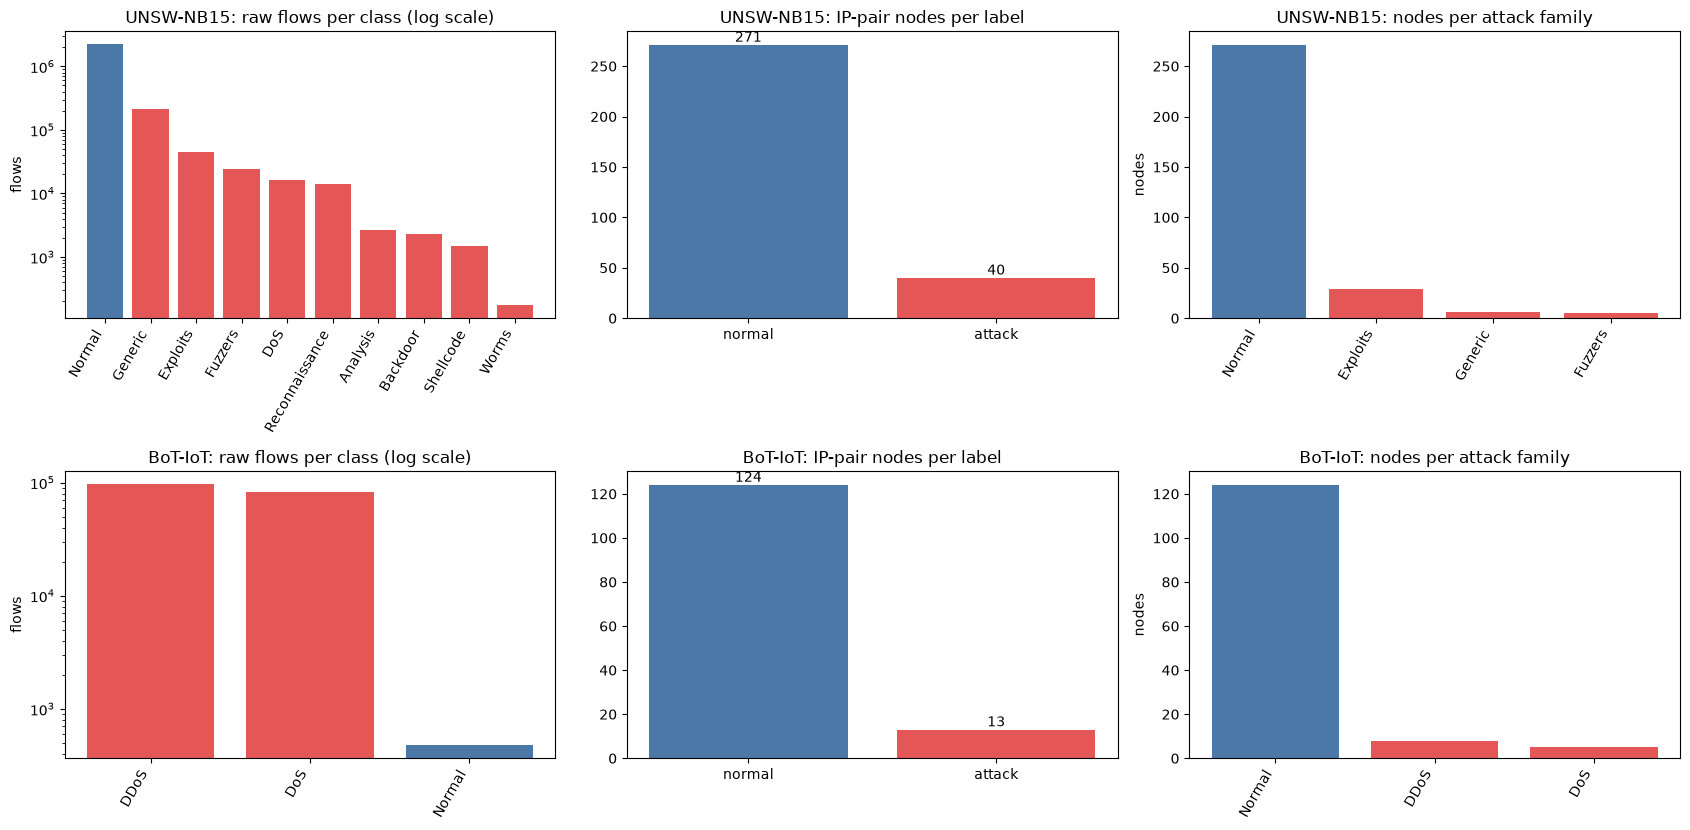

In [7]:
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(17, 4.2 * len(DATASETS)))
for r, name in enumerate(DATASETS):
    st, p = STATS[name], PAIRS[name]
    ax = axes[r, 0]
    fc = pd.Series(st["family_counts"]).sort_values(ascending=False)
    ax.bar(range(len(fc)), fc.values, color=["#4c78a8" if k == "Normal" else "#e45756" for k in fc.index]); ax.set_yscale("log")
    ax.set_xticks(range(len(fc))); ax.set_xticklabels(fc.index, rotation=60, ha="right"); ax.set_title(f"{name}: raw flows per class (log scale)"); ax.set_ylabel("flows")
    ax = axes[r, 1]
    lc = p["label"].map({0: "normal", 1: "attack"}).value_counts()
    ax.bar(lc.index, lc.values, color=["#4c78a8" if k == "normal" else "#e45756" for k in lc.index]); ax.set_title(f"{name}: IP-pair nodes per label")
    for i, v in enumerate(lc.values): ax.text(i, v, str(v), ha="center", va="bottom")
    ax = axes[r, 2]
    nf = p["family"].value_counts()
    ax.bar(range(len(nf)), nf.values, color=["#4c78a8" if k == "Normal" else "#e45756" for k in nf.index])
    ax.set_xticks(range(len(nf))); ax.set_xticklabels(nf.index, rotation=60, ha="right"); ax.set_title(f"{name}: nodes per attack family"); ax.set_ylabel("nodes")
plt.tight_layout(); plt.show()

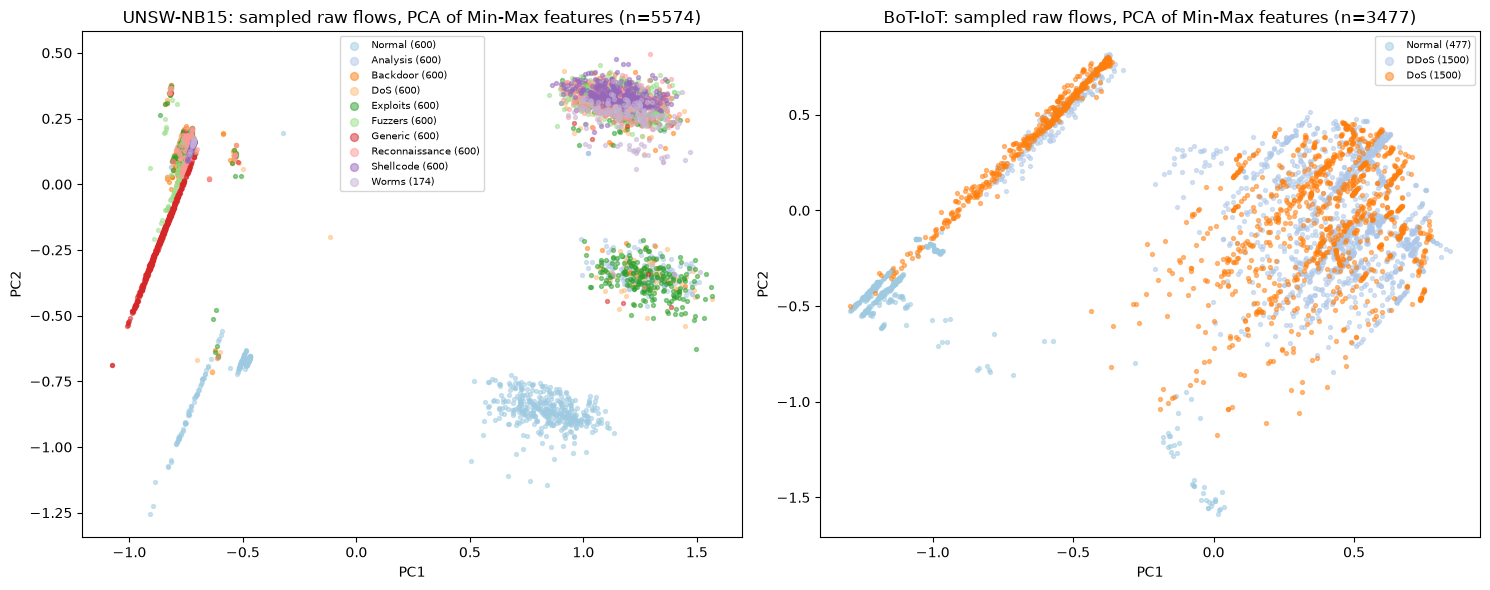

In [8]:
# 2-D view of REAL raw flows (stratified sample), coloured by ground-truth family. Exploration only: nothing is trained on this PCA.
fig, axes = plt.subplots(1, len(DATASETS), figsize=(7.5 * len(DATASETS), 6))
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    fs = FLOW_SAMPLE[name]
    feats = [c for c in fs.columns if c not in ("label", "family")]
    Z = PCA(2, random_state=SEED).fit_transform(MinMaxScaler().fit_transform(fs[feats].values))
    fams = sorted(fs["family"].unique(), key=lambda f: (f != "Normal", f))
    cmap = plt.get_cmap("tab20")
    for i, f in enumerate(fams):
        m = (fs["family"] == f).values
        ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, color="#9ecae1" if f == "Normal" else cmap(i % 20), label=f"{f} ({m.sum()})")
    ax.set_title(f"{name}: sampled raw flows, PCA of Min-Max features (n={len(fs)})"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

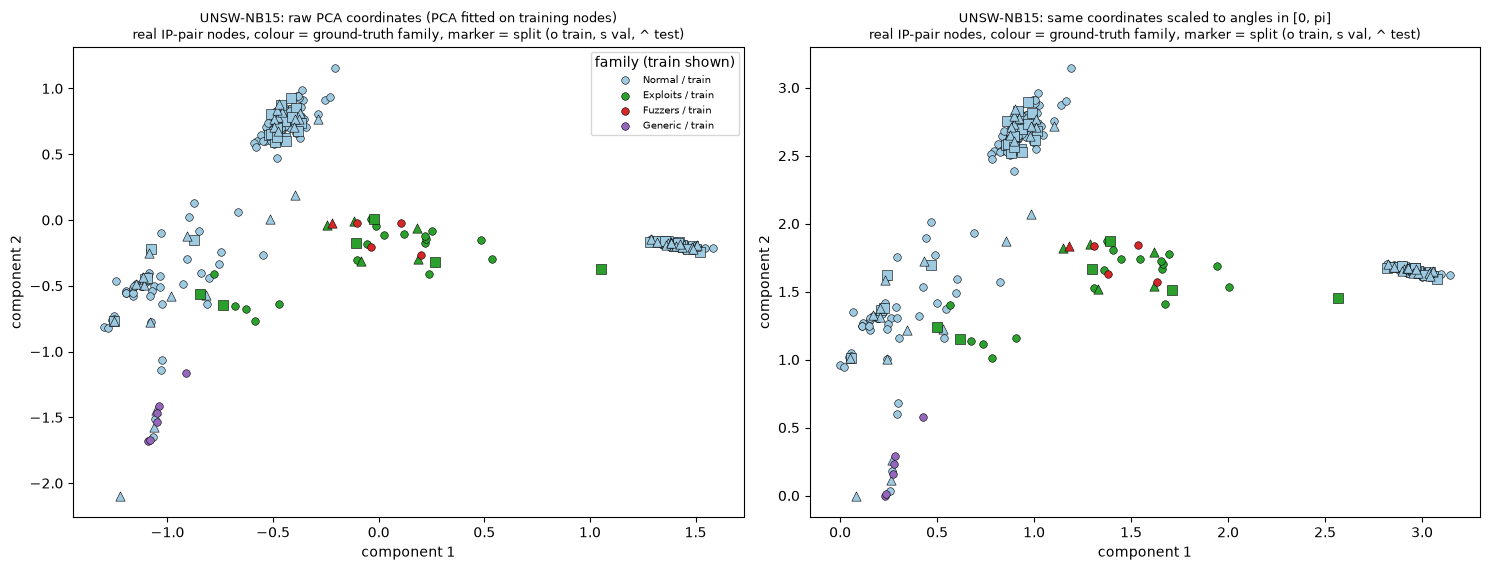

UNSW-NB15: PCA explained variance ratio (4 components, training nodes): [0.485 0.183 0.12  0.065]


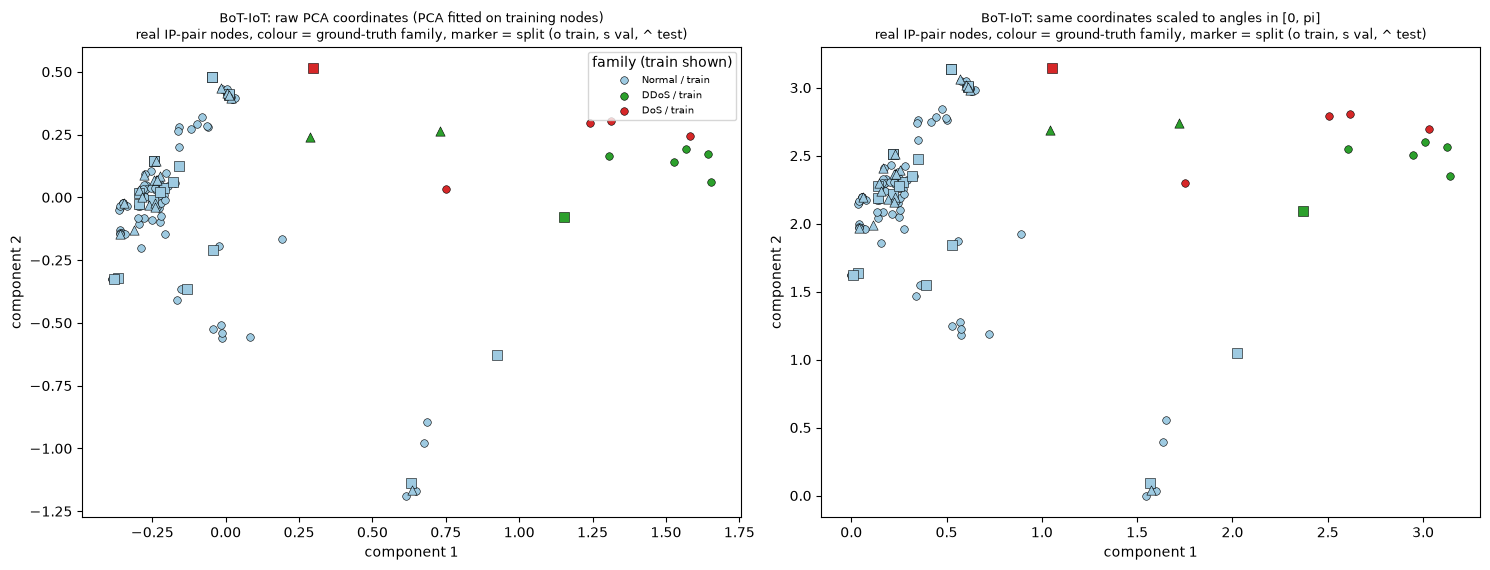

BoT-IoT: PCA explained variance ratio (4 components, training nodes): [0.502 0.213 0.119 0.079]


In [9]:
# The nodes the model sees: PCA fitted on the TRAINING nodes only (seed 42 split), first two coordinates, then the same scaled to [0, pi]
def family_colors(fams):
    cmap = plt.get_cmap("tab20"); order = sorted(set(fams), key=lambda f: (f != "Normal", f))
    return {f: ("#9ecae1" if f == "Normal" else cmap((i * 2 + 2) % 20)) for i, f in enumerate(order)}

for name in DATASETS:
    sp, pr = SPLITS[name], PAIRS[name]
    P, tr = sp["P"], sp["idx"]["train"]
    fam = pr["family"].values; col = family_colors(fam)
    lo, hi = P[tr].min(0), P[tr].max(0)
    Pang = np.clip((P - lo) / (hi - lo + 1e-12), 0, 1) * np.pi        # scaling fitted on training nodes, test angles clipped to [0, pi]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
    for ax, C, ttl in ((axes[0], P, "raw PCA coordinates (PCA fitted on training nodes)"), (axes[1], Pang, "same coordinates scaled to angles in [0, pi]")):
        for f in sorted(set(fam), key=lambda f: (f != "Normal", f)):
            for split, mk in (("train", "o"), ("val", "s"), ("test", "^")):
                ii = sp["idx"][split]; m = fam[ii] == f
                if m.any():
                    ax.scatter(C[ii][m, 0], C[ii][m, 1], s=45 if mk != "o" else 30, marker=mk, color=col[f], edgecolor="k", linewidth=0.4,
                               label=f"{f} / {split}" if split == "train" else None)
        ax.set_title(f"{name}: {ttl}\nreal IP-pair nodes, colour = ground-truth family, marker = split (o train, s val, ^ test)", fontsize=9)
        ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    axes[0].legend(fontsize=7, title="family (train shown)", loc="best")
    plt.tight_layout(); plt.show()
    print(f"{name}: PCA explained variance ratio (4 components, training nodes):", np.round(sp["pca"].explained_variance_ratio_, 3))

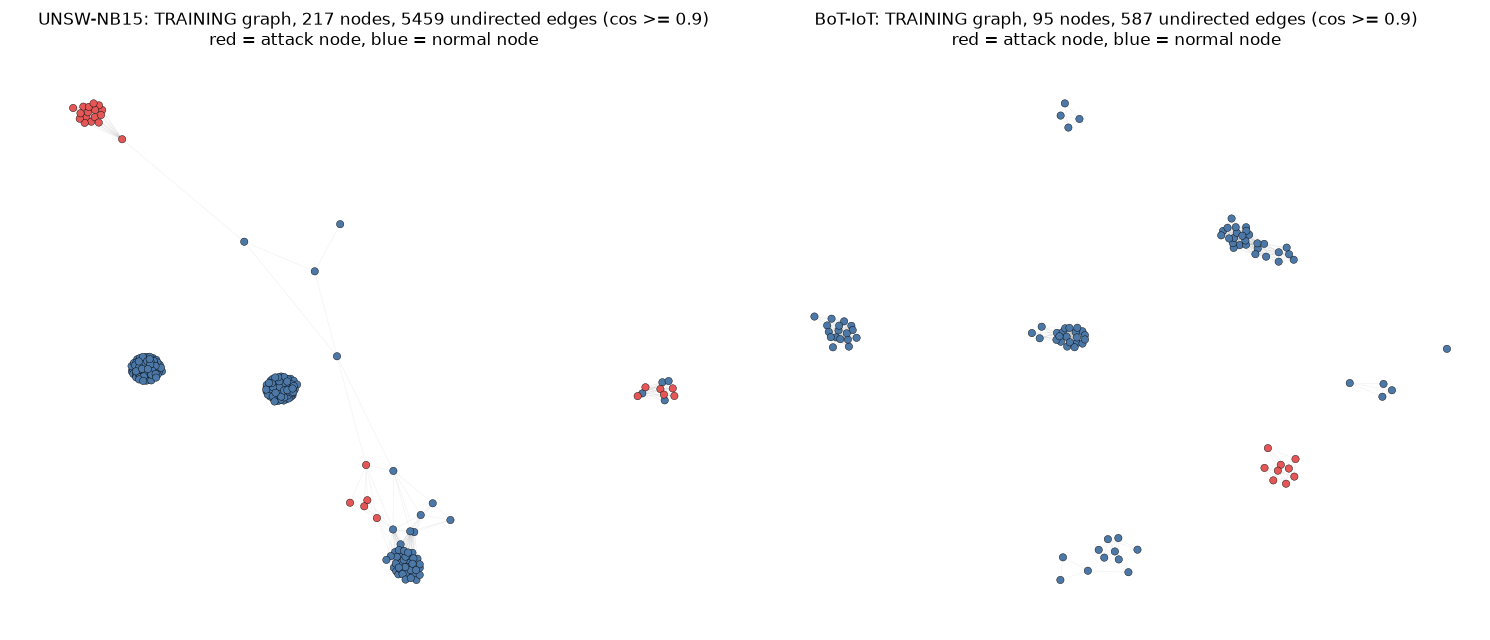

In [10]:
import networkx as nx
fig, axes = plt.subplots(1, len(DATASETS), figsize=(7.5 * len(DATASETS), 6.5))
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    g = SPLITS[name]["graph"]["train"]
    G = nx.from_numpy_array(g["A"].numpy())
    pos = nx.spring_layout(G, seed=SEED, k=1.5 / math.sqrt(len(G)))
    colors = ["#e45756" if v > 0.5 else "#4c78a8" for v in g["y"].numpy()]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.05, width=0.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=28, edgecolors="k", linewidths=0.3)
    ax.set_title(f"{name}: TRAINING graph, {G.number_of_nodes()} nodes, {G.number_of_edges()} undirected edges (cos >= {SIM_THRESHOLD})\nred = attack node, blue = normal node"); ax.axis("off")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The quantum part of Q-AGNN is evaluated **once per node**: the 4 PCA coordinates of a node are loaded by `RY` angle encoding (Eq. 5), followed by an `EfficientSU2` ansatz with linear CNOT entanglement (Eq. 6-7), and the embedding is the vector of Pauli-Z expectation values (Eq. 8). With `PQC_REPS = 1` the ansatz is exactly Eq. 6: `RY, RZ` on every qubit, CNOT chain `0-1, 1-2, 2-3`, `RY, RZ` on every qubit.

Assumptions where the paper is silent (also listed in the table above): number of layers `L = 1`; observables are Pauli-Z on every qubit; initial weights uniform in `[-pi, pi]`; the PCA coordinates are used directly as radians.

The cell below builds that circuit with Qiskit and draws it. Training with autograd over 200+ nodes per epoch would be very slow through the Qiskit primitives, so training uses a small exact state-vector simulator written in PyTorch; **a cell asserts that this simulator reproduces Qiskit's `StatevectorEstimator` on the drawn circuit** (the same 4 expectation values for random inputs and weights).

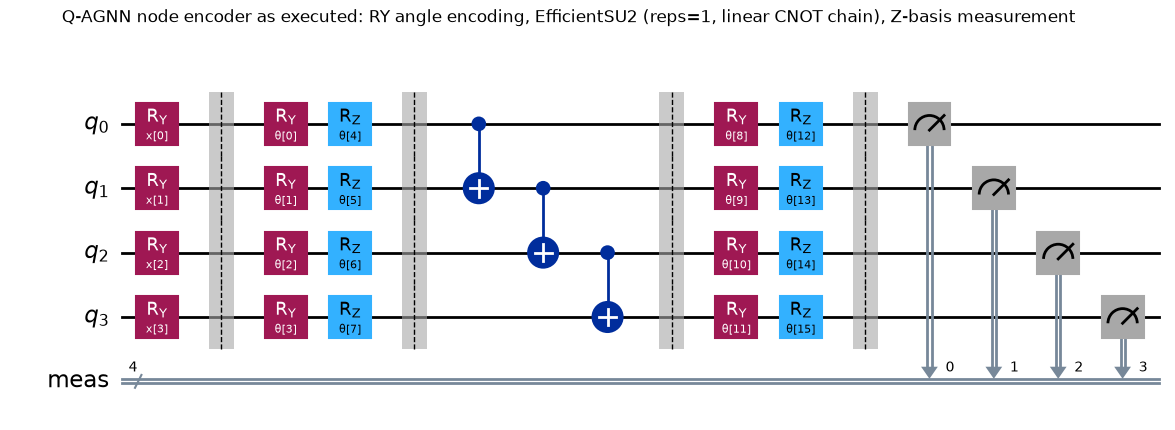

qubits: 4 | depth: 8 | trainable weights: 16 | data parameters: 4
gate counts: {'ry': 12, 'rz': 8, 'barrier': 3, 'cx': 3}


In [11]:
from IPython.display import display
def build_qiskit_pqc(n=N_QUBITS, reps=PQC_REPS):
    x = ParameterVector("x", n)                                   # data (node features)
    enc = QuantumCircuit(n, name="angle_encoding")
    for k in range(n): enc.ry(x[k], k)                            # Eq. 5
    ans = efficient_su2(n, su2_gates=["ry", "rz"], entanglement="linear", reps=reps, insert_barriers=True)   # Eq. 6-7
    qc = QuantumCircuit(n); qc.compose(enc, inplace=True); qc.barrier(); qc.compose(ans, inplace=True)
    return qc, x, ans

qc, XPARAMS, ANSATZ = build_qiskit_pqc()
WEIGHT_PARAMS = sorted(ANSATZ.parameters, key=lambda p: p.index)
N_WEIGHTS = len(WEIGHT_PARAMS)
qc_meas = qc.copy(); qc_meas.measure_all()                      # version used when sampling bitstrings (SamplerQNN / hardware)
fig = qc_meas.draw("mpl", fold=-1, style="iqp")
fig.suptitle("Q-AGNN node encoder as executed: RY angle encoding, EfficientSU2 (reps=1, linear CNOT chain), Z-basis measurement", y=1.02)
display(fig); plt.close(fig)
flat = qc
print("qubits:", qc.num_qubits, "| depth:", flat.depth(), "| trainable weights:", N_WEIGHTS, "| data parameters:", len(XPARAMS))
print("gate counts:", dict(flat.count_ops()))

In [12]:
# --- Exact, differentiable state-vector simulator in PyTorch for the same circuit (used for training) ---
def _ry(a):                                   # (B,) -> (B,2,2) complex
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
def _rz(a):                                   # scalar -> (2,2) complex
    return torch.diag(torch.stack([torch.exp(-0.5j * a), torch.exp(0.5j * a)]))

def _apply1(psi, U, q, n):
    B = psi.shape[0]
    t = torch.movedim(psi.reshape((B,) + (2,) * n), 1 + q, -1)
    sh = t.shape; t = t.reshape(B, -1, 2)
    t = t @ (U.T if U.dim() == 2 else U.transpose(1, 2))
    return torch.movedim(t.reshape(sh), -1, 1 + q).reshape(B, -1)

def _cnot_perm(c, t, n):
    idx = np.arange(2 ** n); cb, tb = n - 1 - c, n - 1 - t
    return torch.tensor(np.where((idx >> cb) & 1, idx ^ (1 << tb), idx))

def _zsigns(n):
    idx = np.arange(2 ** n)
    return torch.tensor(np.stack([1 - 2 * ((idx >> (n - 1 - q)) & 1) for q in range(n)], 1), dtype=torch.float64)

def _kron(ms):
    out = ms[0]
    for m in ms[1:]: out = torch.kron(out, m)
    return out

_BITS = {}
def _bits(n):
    if n not in _BITS:
        idx = np.arange(2 ** n); _BITS[n] = torch.tensor(np.stack([(idx >> (n - 1 - q)) & 1 for q in range(n)], 1).astype(bool))   # (2^n, n); qubit 0 = most significant bit
    return _BITS[n]

def ansatz_unitary(theta, n=N_QUBITS, reps=PQC_REPS):
    """Unitary of the EfficientSU2 part, gate order identical to the drawn circuit: [RY layer, RZ layer, CNOT chain] x reps, then RY, RZ."""
    U = torch.eye(2 ** n, dtype=torch.complex128); p = 0
    for layer in range(reps + 1):
        RY = _kron(list(_ry(theta[p:p + n]))); p += n                      # RY on all qubits (Kronecker product)
        ph = torch.exp(-0.5j * theta[p:p + n]); p += n
        DZ = _kron([torch.stack([ph[k], ph[k].conj()]) for k in range(n)])  # RZ on all qubits is diagonal
        U = (DZ[:, None] * RY) @ U
        if layer < reps:
            for k in range(n - 1): U = U[_cnot_perm(k, k + 1, n), :]        # CNOT(k, k+1)
    return U

def encode_product_state(x, n=N_QUBITS):
    """RY(x_k)|0> on every qubit (Eq. 5) is a real product state: amplitude = prod_q (cos(x_q/2) or sin(x_q/2))."""
    c, s = torch.cos(x / 2), torch.sin(x / 2)
    return torch.where(_bits(n)[None], s[:, None, :], c[:, None, :]).prod(-1).to(torch.complex128)
def pqc_state(x, theta, n=N_QUBITS, reps=PQC_REPS):
    """x: (B,n) angles, theta: (2n(reps+1),) weights -> (B,2^n) complex output states |phi_i> = U(theta) |psi_i> (Eq. 5-7)."""
    return encode_product_state(x, n) @ ansatz_unitary(theta, n, reps).T

def pqc_embedding(x, theta, n=N_QUBITS, reps=PQC_REPS):
    """Eq. 8 with O_k = Pauli-Z on qubit k: z_k = <phi|Z_k|phi> in [-1, 1]."""
    return (pqc_state(x, theta, n, reps).abs() ** 2) @ _zsigns(n)

# ---- equivalence check against the executed Qiskit circuit and StatevectorEstimator ----
g = np.random.default_rng(SEED)
xs, ths = g.uniform(-1.5, 1.5, (12, N_QUBITS)), g.uniform(-np.pi, np.pi, (12, N_WEIGHTS))
obs = [SparsePauliOp("I" * (N_QUBITS - 1 - k) + "Z" + "I" * k) for k in range(N_QUBITS)]    # Z on qubit k (Qiskit labels are little-endian)
def _row(i):
    d = {**{XPARAMS[k]: xs[i, k] for k in range(N_QUBITS)}, **{w: ths[i, w.index] for w in WEIGHT_PARAMS}}
    return [d[p] for p in qc.parameters]
vals = np.array([_row(i) for i in range(len(xs))])
est = StatevectorEstimator(seed=SEED).run([(qc, [obs], vals[:, None, :])]).result()[0].data.evs      # shape (12, 4)
mine = torch.stack([pqc_embedding(torch.tensor(xs[i:i + 1]), torch.tensor(ths[i]))[0] for i in range(len(xs))]).numpy()
print("max |torch simulator - Qiskit StatevectorEstimator| =", float(np.abs(est - mine).max()))
assert np.allclose(est, mine, atol=1e-9), "torch simulator does not match the Qiskit circuit"
print("EQUIVALENCE ASSERTION PASSED: the PyTorch simulator used for training is the drawn Qiskit circuit.")

max |torch simulator - Qiskit StatevectorEstimator| = 5.551115123125783e-16
EQUIVALENCE ASSERTION PASSED: the PyTorch simulator used for training is the drawn Qiskit circuit.


FakeTorino: physical qubits used: [0, 1, 2, 3]
ISA depth: 29 | ops: {'rz': 44, 'sx': 30, 'barrier': 3, 'cz': 3} | trainable weights: 16


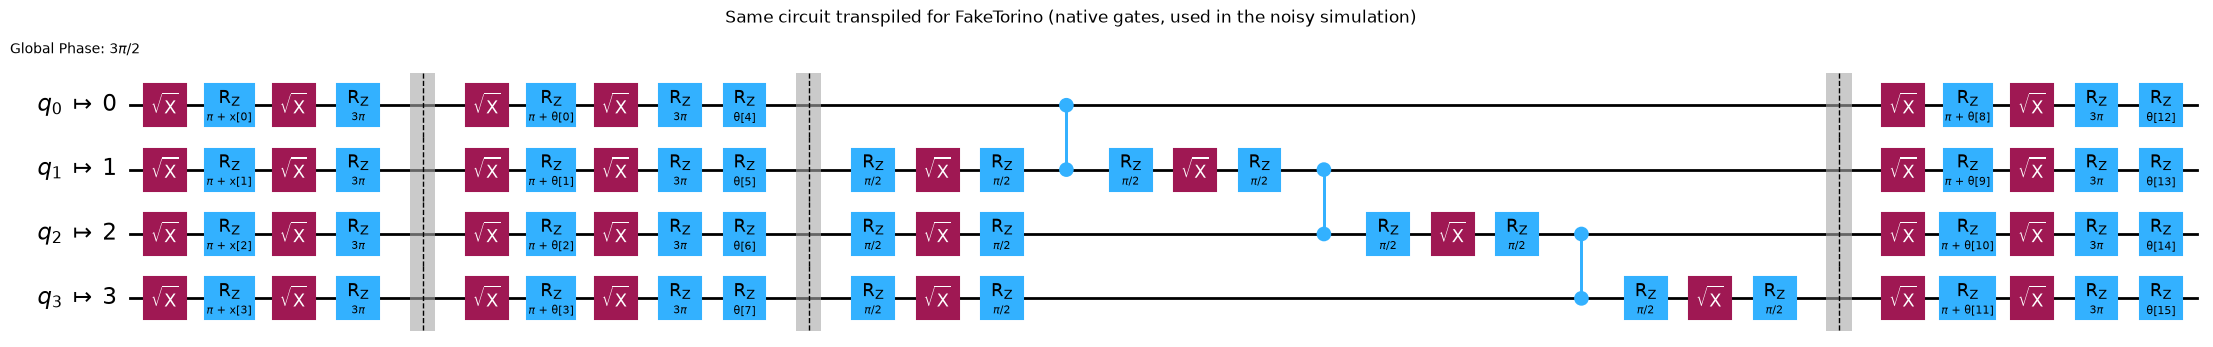

In [13]:
# The circuit that actually runs in the noisy simulation (Section 8): the same ansatz transpiled to the native gate set of an IBM device
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import fake_provider
FAKE_NOISY = getattr(fake_provider, NOISY_BACKEND)()
PM_NOISY = generate_preset_pass_manager(backend=FAKE_NOISY, optimization_level=1, seed_transpiler=SEED)
ISA = PM_NOISY.run(qc)
print(f"{NOISY_BACKEND}: physical qubits used:", sorted({ISA.find_bit(q).index for inst in ISA.data for q in inst.qubits}))
print("ISA depth:", ISA.depth(), "| ops:", dict(ISA.count_ops()), "| trainable weights:", N_WEIGHTS)
fig = ISA.draw("mpl", idle_wires=False, fold=-1, style="iqp")
fig.suptitle(f"Same circuit transpiled for {NOISY_BACKEND} (native gates, used in the noisy simulation)", y=1.0)
display(fig); plt.close(fig)

## 3. The Q-AGNN model, the ablation variants and the seven classical GNN baselines

`QAGNN` below follows Algorithm 1: PQC embedding of every node (Eq. 8), attention-weighted one-hop and two-hop aggregation with `A` and `A^2` (Eq. 9-11), fusion `h = tanh(z + z1 + z2)` (Eq. 12) and an MLP (Eq. 13). The same class with switches gives the six ablation variants of Table 6: no attention (`alpha = 1`), one hop only, no graph at all (node-wise QNN) and a classical encoder instead of the PQC.

The seven classical baselines are dense-matrix PyTorch re-implementations of the PyG layers used in the paper. Their hidden width is chosen so that their parameter count is as close as possible to Q-AGNN's, as in the paper.

In [14]:
def row_normalise(M):
    d = M.sum(1, keepdim=True)
    return torch.where(d > 0, M / d.clamp(min=1e-12), torch.zeros_like(M))   # CHOICE: row-normalised A and A^2 (isolated nodes keep a zero row)

class QAGNN(nn.Module):
    """Q-AGNN (Eq. 5-13) and its ablations. encoder: 'pqc' (4-qubit EfficientSU2) or 'mlp' (capacity-matched classical encoder)."""
    def __init__(self, encoder="pqc", use_att=True, hops=2, use_graph=True, hidden=MLP_HIDDEN, n=N_QUBITS, reps=PQC_REPS):
        super().__init__()
        self.encoder, self.use_att, self.hops, self.use_graph, self.n, self.reps = encoder, use_att, hops, use_graph, n, reps
        if encoder == "pqc":
            self.theta = nn.Parameter((torch.rand(2 * n * (reps + 1)) * 2 - 1) * math.pi)       # CHOICE: uniform in [-pi, pi]
        else:
            self.enc = nn.Sequential(nn.Linear(n, 2), nn.Tanh(), nn.Linear(2, n), nn.Tanh())   # classical encoder, bounded in [-1,1] like the PQC
        if use_att and use_graph:
            self.att_w = nn.Parameter(torch.randn(hops, n) * 0.1); self.att_b = nn.Parameter(torch.zeros(hops))
        self.mlp = nn.Sequential(nn.Linear(n, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def embed(self, X):
        return pqc_embedding(X, self.theta, self.n, self.reps) if self.encoder == "pqc" else self.enc(X)

    def forward(self, g):
        z = g["Z"] if g.get("Z") is not None else self.embed(g["X"])        # precomputed (e.g. noisy) embeddings can be injected
        if not self.use_graph:
            h = torch.tanh(z)
        else:
            N = z.shape[0]
            if "A1n" not in g: g["A1n"] = row_normalise(g["A"]); g["A2n"] = row_normalise(g["A"] @ g["A"])
            agg = z
            for k, Ah in enumerate([g["A1n"], g["A2n"]][: self.hops]):
                alpha = N * torch.softmax(z @ self.att_w[k] + self.att_b[k], dim=0) if self.use_att else torch.ones(N, dtype=z.dtype)
                agg = agg + Ah @ (alpha[:, None] * z)                         # Eq. 10 / 11
            h = torch.tanh(agg)                                              # Eq. 12
        return self.mlp(h).squeeze(-1)                                       # Eq. 13 (logit)

# ------------------------------ classical GNN baselines (dense, two conv layers + linear head) ------------------------------
def _sym_norm(A):
    Ah = A + torch.eye(A.shape[0], dtype=A.dtype); d = Ah.sum(1)
    return Ah / torch.sqrt(d[:, None] * d[None, :])

def _masked_softmax(S, mask):
    S = S.masked_fill(~mask, -1e30); P = torch.softmax(S, dim=1)
    return P * mask                                                          # rows without neighbours become zero

class Conv(nn.Module):
    def __init__(self, kind, i, o):
        super().__init__(); self.kind = kind
        if kind == "GCN": self.lin = nn.Linear(i, o)
        elif kind in ("GraphSAGE", "ClusterGCN"): self.l = nn.Linear(i, o); self.r = nn.Linear(i, o, bias=False)
        elif kind == "GINConv": self.mlp = nn.Sequential(nn.Linear(i, o), nn.ReLU(), nn.Linear(o, o))
        elif kind in ("GAT", "SuperGAT"):
            self.lin = nn.Linear(i, o, bias=False); self.a_src = nn.Parameter(torch.randn(o) * 0.1); self.a_dst = nn.Parameter(torch.randn(o) * 0.1); self.bias = nn.Parameter(torch.zeros(o))
        elif kind == "TransformerConv":
            self.q = nn.Linear(i, o); self.k = nn.Linear(i, o); self.v = nn.Linear(i, o); self.root = nn.Linear(i, o, bias=False)
    def forward(self, h, A):
        k, N = self.kind, h.shape[0]
        if k == "GCN": return self.lin(_sym_norm(A) @ h)
        if k == "GraphSAGE": return self.l(row_normalise(A) @ h) + self.r(h)                       # mean aggregator
        if k == "ClusterGCN":
            Ah = A + torch.eye(N, dtype=A.dtype); return self.l((Ah / Ah.sum(1, keepdim=True)) @ h) + self.r(h)
        if k == "GINConv": return self.mlp(h + A @ h)                                              # eps = 0
        if k in ("GAT", "SuperGAT"):
            Wh = self.lin(h); mask = (A + torch.eye(N, dtype=A.dtype)) > 0
            go = F.leaky_relu((Wh @ self.a_src)[:, None] + (Wh @ self.a_dst)[None, :], 0.2)          # Eq. 4
            S = go if k == "GAT" else F.leaky_relu((Wh @ Wh.T) * torch.sigmoid(go), 0.2)             # SuperGAT 'MX' attention (no auxiliary link loss)
            return _masked_softmax(S, mask) @ Wh + self.bias
        if k == "TransformerConv":
            S = (self.q(h) @ self.k(h).T) / math.sqrt(self.q.out_features)
            return _masked_softmax(S, A > 0) @ self.v(h) + self.root(h)

class DenseGNN(nn.Module):
    def __init__(self, kind, hidden, n_in=N_QUBITS):
        super().__init__(); self.c1, self.c2, self.head = Conv(kind, n_in, hidden), Conv(kind, hidden, hidden), nn.Linear(hidden, 1)
    def forward(self, g):
        h = F.relu(self.c1(g["X"], g["A"])); h = F.relu(self.c2(h, g["A"])); return self.head(h).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters())
TARGET_PARAMS = n_params(QAGNN())
def matched_hidden(kind):
    return min(range(2, 65), key=lambda h: abs(n_params(DenseGNN(kind, h)) - TARGET_PARAMS))
BASELINES = ["GCN", "GAT", "GraphSAGE", "ClusterGCN", "GINConv", "SuperGAT", "TransformerConv"]
HIDDEN_MATCHED = {k: matched_hidden(k) for k in BASELINES}
ABLATIONS = {
    "Q-AGNN":          dict(encoder="pqc", use_att=True,  hops=2, use_graph=True),
    "PQC w/o Att":     dict(encoder="pqc", use_att=False, hops=2, use_graph=True),
    "1-Hop + Att":     dict(encoder="pqc", use_att=True,  hops=1, use_graph=True),
    "1-Hop w/o Att":   dict(encoder="pqc", use_att=False, hops=1, use_graph=True),
    "Node-wise QNN":   dict(encoder="pqc", use_att=False, hops=1, use_graph=False),
    "MLP + Att":       dict(encoder="mlp", use_att=True,  hops=2, use_graph=True),
    "MLP w/o Att":     dict(encoder="mlp", use_att=False, hops=2, use_graph=True),
}
def make_model(name):
    if name in ABLATIONS: return QAGNN(**ABLATIONS[name])
    return DenseGNN(name, HIDDEN_MATCHED[name])
print("Q-AGNN parameters:", TARGET_PARAMS, "(16 PQC weights + 10 attention + 97 MLP)")
print("classical encoder of the MLP ablations:", n_params(QAGNN(encoder="mlp").enc), "parameters (PQC: %d weights)" % (2 * N_QUBITS * (PQC_REPS + 1)))
print("baseline hidden widths and parameter counts:", {k: (HIDDEN_MATCHED[k], n_params(make_model(k))) for k in BASELINES})

Q-AGNN parameters: 123 (16 PQC weights + 10 attention + 97 MLP)
classical encoder of the MLP ablations: 22 parameters (PQC: 16 weights)
baseline hidden widths and parameter counts: {'GCN': (8, 121), 'GAT': (7, 127), 'GraphSAGE': (6, 139), 'ClusterGCN': (6, 139), 'GINConv': (5, 121), 'SuperGAT': (7, 127), 'TransformerConv': (3, 106)}


### Training loop and metrics

Adam with learning rate 0.01 and weight decay 1e-2, BCE with logits on all training nodes of the training graph (the whole graph is one batch), validation loss on the validation graph after every epoch, early stopping after 30 epochs without improvement (the weights of the best validation epoch are restored), prediction threshold 0.5. Metrics follow the paper: accuracy, macro precision / recall / F1, and FPR, FNR, specificity with **attack as the positive class**.

In [15]:
import copy
bce = nn.BCEWithLogitsLoss()
COLS = ["Acc", "Prec", "Rec", "F1", "FPR", "FNR", "Spec"]

def to_graph(g): return {k: v for k, v in g.items()}

def train_model(model, graphs, max_epochs=None, patience=PATIENCE, lr=LR, wd=WEIGHT_DECAY):
    max_epochs = max_epochs or MAX_EPOCHS
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    gtr, gva = graphs["train"], graphs["val"]
    best, best_state, bad, hist = float("inf"), copy.deepcopy(model.state_dict()), 0, []
    for ep in range(max_epochs):
        model.train(); opt.zero_grad()
        loss = bce(model(gtr), gtr["y"]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): vloss = bce(model(gva), gva["y"]).item()
        hist.append((loss.item(), vloss))
        if vloss < best - 1e-6: best, best_state, bad = vloss, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return hist

def metrics_from(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    def prf(tp_, fp_, fn_):
        p = tp_ / (tp_ + fp_) if tp_ + fp_ else 0.0; r = tp_ / (tp_ + fn_) if tp_ + fn_ else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)
    p1, r1, f1 = prf(tp, fp, fn); p0, r0, f0 = prf(tn, fn, fp)
    return dict(Acc=(tp + tn) / len(y_true), Prec=(p0 + p1) / 2, Rec=(r0 + r1) / 2, F1=(f0 + f1) / 2,
                FPR=fp / (fp + tn) if fp + tn else 0.0, FNR=fn / (fn + tp) if fn + tp else 0.0, Spec=tn / (tn + fp) if tn + fp else 0.0,
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

def evaluate(model, g):
    model.eval()
    with torch.no_grad(): prob = torch.sigmoid(model(g)).numpy()
    return metrics_from(g["y"].numpy().astype(int), (prob >= 0.5).astype(int)), prob

def run_model(name, sp, seed, graphs=None):
    set_all_seeds(seed)
    graphs = graphs or {k: to_graph(v) for k, v in sp["graph"].items()}
    model = make_model(name); t0 = time.time()
    hist = train_model(model, graphs)
    m, prob = evaluate(model, graphs["test"]); m["seconds"] = time.time() - t0; m["epochs"] = len(hist)
    return m, hist, model

In [16]:
ALL_MODELS = list(ABLATIONS) + BASELINES
t0 = time.time(); RUN42 = {}
for name in DATASETS:
    for mname in ALL_MODELS:
        m, hist, model = run_model(mname, SPLITS[name], SEED)
        RUN42[(name, mname)] = dict(metrics=m, hist=hist, model=model)
    print(f"{name}: all {len(ALL_MODELS)} models trained (seed {SEED}), elapsed {time.time() - t0:.0f} s")

UNSW-NB15: all 14 models trained (seed 42), elapsed 136 s


BoT-IoT: all 14 models trained (seed 42), elapsed 176 s


In [17]:
COLS = ["Acc", "Prec", "Rec", "F1", "FPR", "FNR", "Spec"]
def table(dataset, models, run=RUN42):
    return pd.DataFrame({m: {c: run[(dataset, m)]["metrics"][c] for c in COLS} for m in models}).T.round(4)

print("TABLE 4 style (noiseless exact simulation, seed 42 split, test graph; attack = positive class)")
for name in DATASETS:
    t = table(name, ["Q-AGNN"] + BASELINES)
    t["epochs"] = [RUN42[(name, m)]["metrics"]["epochs"] for m in t.index]
    n_te = len(SPLITS[name]["graph"]["test"]["y"]); n_att = int(SPLITS[name]["graph"]["test"]["y"].sum())
    print(f"\n{name}  (test graph: {n_te} nodes, {n_att} attack nodes)"); print(t.to_string())

TABLE 4 style (noiseless exact simulation, seed 42 split, test graph; attack = positive class)

UNSW-NB15  (test graph: 47 nodes, 6 attack nodes)
                    Acc    Prec     Rec      F1     FPR  FNR    Spec  epochs
Q-AGNN           0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024     189
GCN              0.8936  0.7727  0.9390  0.8205  0.1220  0.0  0.8780     601
GAT              0.8936  0.7727  0.9390  0.8205  0.1220  0.0  0.8780     128
GraphSAGE        0.9787  0.9286  0.9878  0.9554  0.0244  0.0  0.9756     185
ClusterGCN       0.9787  0.9286  0.9878  0.9554  0.0244  0.0  0.9756     180
GINConv          0.8723  0.4362  0.5000  0.4659  0.0000  1.0  1.0000     249
SuperGAT         0.9574  0.8750  0.9756  0.9161  0.0488  0.0  0.9512     111
TransformerConv  0.9787  0.9286  0.9878  0.9554  0.0244  0.0  0.9756     357

BoT-IoT  (test graph: 21 nodes, 2 attack nodes)
                    Acc    Prec  Rec     F1  FPR  FNR  Spec  epochs
Q-AGNN           0.9048  0.4524  0.5  0.475 

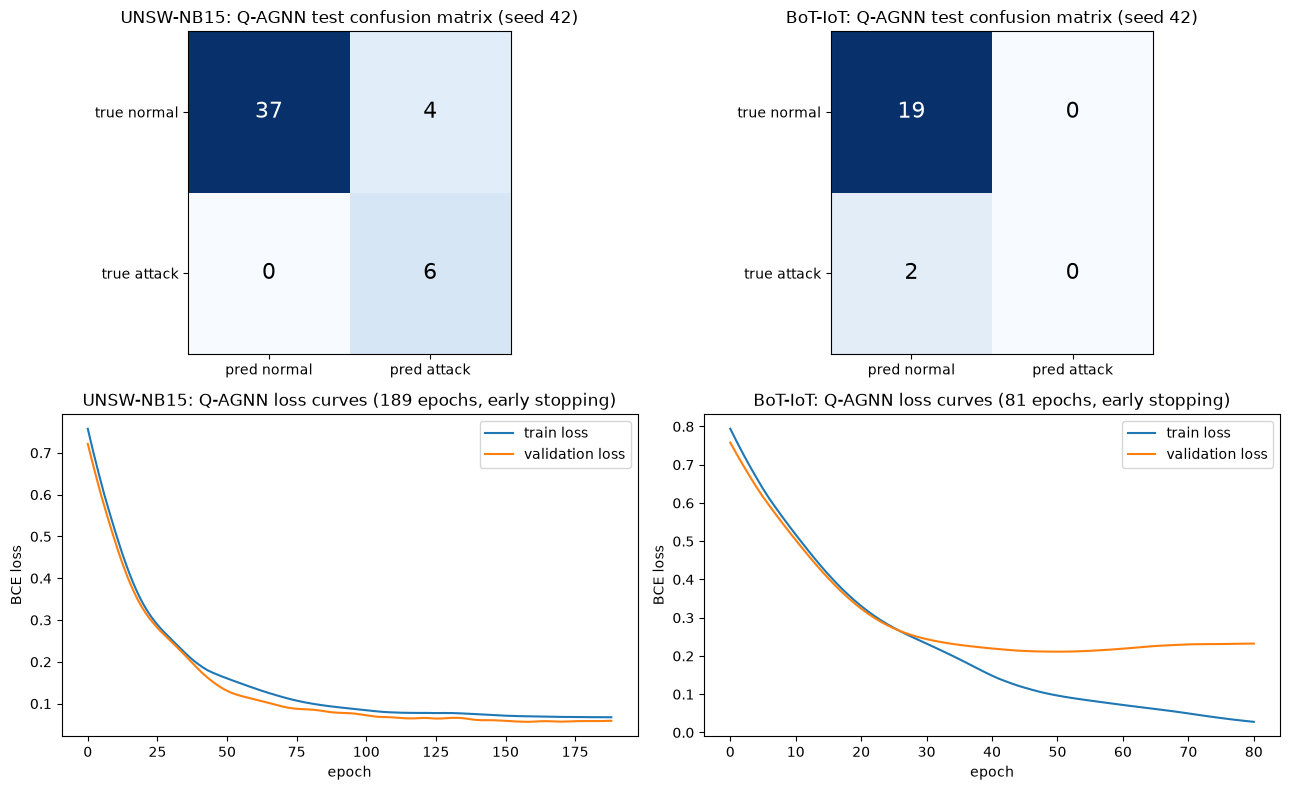

In [18]:
# Q-AGNN confusion matrices on the test graph (seed 42) and training / validation loss curves (Fig. 4 style)
fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.5 * len(DATASETS), 8))
for c, name in enumerate(DATASETS):
    m = RUN42[(name, "Q-AGNN")]["metrics"]
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    ax = axes[0, c]; im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred normal", "pred attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true normal", "true attack"])
    ax.set_title(f"{name}: Q-AGNN test confusion matrix (seed {SEED})")
    ax = axes[1, c]; h = np.array(RUN42[(name, "Q-AGNN")]["hist"])
    ax.plot(h[:, 0], label="train loss"); ax.plot(h[:, 1], label="validation loss"); ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.legend()
    ax.set_title(f"{name}: Q-AGNN loss curves ({len(h)} epochs, early stopping)")
plt.tight_layout(); plt.show()

## 4. Ablation study (Table 6) on the seed-42 split

Six variants of Q-AGNN, as in Section 7 of the paper: remove attention (`alpha = 1`), use one hop instead of two, both, remove the graph (node-wise QNN), and replace the PQC by a capacity-matched classical MLP encoder (with and without attention).

In [19]:
print("TABLE 6 style (seed 42 split, test graph, noiseless)")
for name in DATASETS:
    t = table(name, list(ABLATIONS)); print(f"\n{name}"); print(t.to_string())

TABLE 6 style (seed 42 split, test graph, noiseless)

UNSW-NB15
                  Acc    Prec     Rec      F1     FPR  FNR    Spec
Q-AGNN         0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024
PQC w/o Att    0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024
1-Hop + Att    0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024
1-Hop w/o Att  0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024
Node-wise QNN  0.9149  0.8000  0.9512  0.8494  0.0976  0.0  0.9024
MLP + Att      0.9574  0.8750  0.9756  0.9161  0.0488  0.0  0.9512
MLP w/o Att    0.9787  0.9286  0.9878  0.9554  0.0244  0.0  0.9756

BoT-IoT
                  Acc    Prec  Rec     F1  FPR  FNR  Spec
Q-AGNN         0.9048  0.4524  0.5  0.475  0.0  1.0   1.0
PQC w/o Att    0.9048  0.4524  0.5  0.475  0.0  1.0   1.0
1-Hop + Att    0.9048  0.4524  0.5  0.475  0.0  1.0   1.0
1-Hop w/o Att  0.9048  0.4524  0.5  0.475  0.0  1.0   1.0
Node-wise QNN  0.9048  0.4524  0.5  0.475  0.0  1.0   1.0
MLP + Att      0.9048  0.4524  0.5  0.475  

## 5. Repeated random splits (mean +/- std)

The paper reports **one** split per dataset with test graphs of only 24 to 47 nodes and 5 to 6 attack nodes, so a single wrong prediction moves accuracy by 2 to 4 points. To see how much of a result is the split, every model is retrained on several different stratified splits (and different initialisations). `FAST_MODE` uses fewer models and splits; the full run uses all 14 models and 5 extra splits.

In [20]:
SEEDS = [SEED] + [SEED + 1 + i for i in range(N_EXTRA_SPLITS)]
MULTI_MODELS = ALL_MODELS if not FAST_MODE else ["Q-AGNN", "PQC w/o Att", "MLP + Att", "Node-wise QNN", "GCN", "GraphSAGE", "TransformerConv"]
MULTI = {}     # (dataset, model) -> list of metric dicts
t0 = time.time()
for name in DATASETS:
    for s in SEEDS:
        sp = SPLITS[name] if s == SEED else make_split(name, s)
        for mname in MULTI_MODELS:
            m = RUN42[(name, mname)]["metrics"] if s == SEED else run_model(mname, sp, s)[0]
            MULTI.setdefault((name, mname), []).append(m)
    print(f"{name}: {len(SEEDS)} splits x {len(MULTI_MODELS)} models done, elapsed {time.time() - t0:.0f} s")

def multi_table(name):
    rows = {}
    for mname in MULTI_MODELS:
        ms = MULTI[(name, mname)]
        rows[mname] = {c: f"{np.mean([m[c] for m in ms]):.3f} +/- {np.std([m[c] for m in ms]):.3f}" for c in ["Acc", "F1", "FPR", "FNR"]}
    return pd.DataFrame(rows).T
for name in DATASETS:
    sizes = [(len(make_split(name, s)["graph"]["test"]["y"]) if s != SEED else len(SPLITS[name]["graph"]["test"]["y"])) for s in SEEDS[:1]]
    print(f"\n{name}: mean +/- std over {len(SEEDS)} splits (seeds {SEEDS}), test graph size {sizes[0]} nodes"); print(multi_table(name).to_string())

UNSW-NB15: 6 splits x 14 models done, elapsed 448 s


BoT-IoT: 6 splits x 14 models done, elapsed 778 s

UNSW-NB15: mean +/- std over 6 splits (seeds [42, 43, 44, 45, 46, 47]), test graph size 47 nodes
                             Acc               F1              FPR              FNR
Q-AGNN           0.965 +/- 0.027  0.926 +/- 0.049  0.028 +/- 0.036  0.083 +/- 0.127
PQC w/o Att      0.972 +/- 0.032  0.945 +/- 0.059  0.028 +/- 0.036  0.028 +/- 0.062
1-Hop + Att      0.972 +/- 0.029  0.943 +/- 0.053  0.024 +/- 0.034  0.056 +/- 0.079
1-Hop w/o Att    0.961 +/- 0.036  0.910 +/- 0.081  0.020 +/- 0.036  0.167 +/- 0.192
Node-wise QNN    0.965 +/- 0.024  0.925 +/- 0.042  0.028 +/- 0.033  0.083 +/- 0.127
MLP + Att        0.975 +/- 0.019  0.949 +/- 0.040  0.024 +/- 0.020  0.028 +/- 0.062
MLP w/o Att      0.979 +/- 0.017  0.955 +/- 0.037  0.020 +/- 0.017  0.028 +/- 0.062
GCN              0.943 +/- 0.029  0.866 +/- 0.074  0.033 +/- 0.044  0.222 +/- 0.248
GAT              0.950 +/- 0.036  0.887 +/- 0.090  0.037 +/- 0.042  0.139 +/- 0.244
GraphSAGE   

## 6. Embedding space: PQC versus classical MLP encoder (Fig. 3)

The paper shows t-SNE plots of the node embeddings produced by the classical MLP encoder and by the PQC (green = normal, red = attack) and argues that PQC embeddings form more compact class clusters. Below, the embeddings `z` of **all** nodes are taken from the trained seed-42 models (`MLP + Att` and `Q-AGNN`), projected with t-SNE, and a silhouette score on the 4-D embeddings (higher means more separated classes) puts a number on the visual impression.

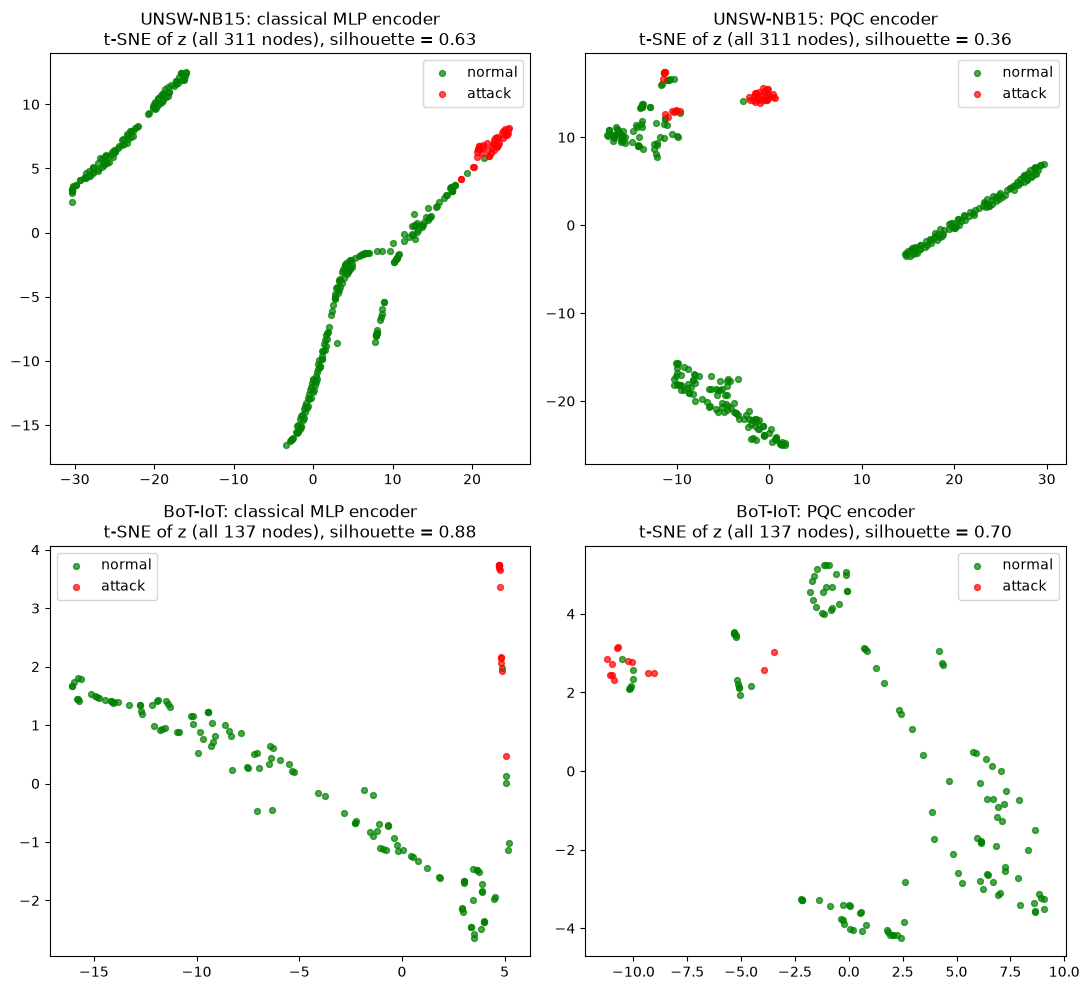

{'UNSW-NB15 / MLP + Att': 0.632, 'UNSW-NB15 / Q-AGNN': 0.36, 'BoT-IoT / MLP + Att': 0.876, 'BoT-IoT / Q-AGNN': 0.697}


In [21]:
from sklearn.metrics import silhouette_score
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(11, 5 * len(DATASETS)))
axes = np.atleast_2d(axes); SIL = {}
for r, name in enumerate(DATASETS):
    sp = SPLITS[name]; Xall = torch.tensor(sp["P"]); yall = sp["y"]
    for c, (mname, ttl) in enumerate((("MLP + Att", "classical MLP encoder"), ("Q-AGNN", "PQC encoder"))):
        mdl = RUN42[(name, mname)]["model"]
        with torch.no_grad(): Z = mdl.embed(Xall).numpy()
        sil = silhouette_score(Z, yall); SIL[(name, mname)] = sil
        E = TSNE(n_components=2, perplexity=min(30, (len(Z) - 1) // 4), random_state=SEED, init="pca").fit_transform(Z)
        ax = axes[r, c]
        for lab, col, nm in ((0, "green", "normal"), (1, "red", "attack")):
            ax.scatter(E[yall == lab, 0], E[yall == lab, 1], s=18, color=col, alpha=0.7, label=nm)
        ax.set_title(f"{name}: {ttl}\nt-SNE of z (all {len(Z)} nodes), silhouette = {sil:.2f}"); ax.legend()
plt.tight_layout(); plt.show()
print({f"{k[0]} / {k[1]}": round(v, 3) for k, v in SIL.items()})

## 7. Sensitivity to the cosine-similarity threshold (Table 3)

The paper varies the threshold on NF-UNSW-NB15 (not available here). We run the same sweep for Q-AGNN on the two datasets we do have, averaged over a few splits.

mean over splits [42, 43, 44]
  dataset  threshold  train_edges    F1   FPR   Acc
UNSW-NB15       0.60        12440 0.875 0.033 0.943
UNSW-NB15       0.70        11974 0.875 0.033 0.943
UNSW-NB15       0.80        11546 0.895 0.033 0.950
UNSW-NB15       0.90        10918 0.895 0.033 0.950
UNSW-NB15       0.95         9962 0.895 0.033 0.950
  BoT-IoT       0.60         2580 0.825 0.000 0.968
  BoT-IoT       0.70         2100 0.825 0.000 0.968
  BoT-IoT       0.80         1696 0.825 0.000 0.968
  BoT-IoT       0.90         1174 0.825 0.000 0.968
  BoT-IoT       0.95          844 0.825 0.000 0.968


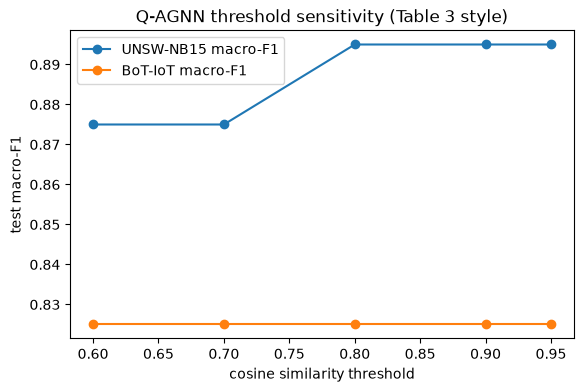

In [22]:
THRESH_SEEDS = [SEED] if FAST_MODE else [SEED + i for i in range(3)]
rows = []
for name in DATASETS:
    for thr in THRESHOLDS:
        res = [run_model("Q-AGNN", make_split(name, s, thr=thr), s)[0] for s in THRESH_SEEDS]
        g = make_split(name, SEED, thr=thr)["graph"]["train"]
        rows.append(dict(dataset=name, threshold=thr, train_edges=int(g["A"].sum()), F1=np.mean([r["F1"] for r in res]), FPR=np.mean([r["FPR"] for r in res]), Acc=np.mean([r["Acc"] for r in res])))
SENS = pd.DataFrame(rows).round(3)
print(f"mean over splits {THRESH_SEEDS}"); print(SENS.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4))
for name in DATASETS:
    d = SENS[SENS.dataset == name]; ax.plot(d.threshold, d.F1, marker="o", label=f"{name} macro-F1")
ax.set_xlabel("cosine similarity threshold"); ax.set_ylabel("test macro-F1"); ax.set_title("Q-AGNN threshold sensitivity (Table 3 style)"); ax.legend(); plt.show()

## 8. Hardware-calibrated noisy simulation (Table 5)

The paper trains and tests with the noise model of an IBM device (Torino for BoT-IoT and UNSW-NB15) imported into `AerSimulator` (density matrix) and read through `BackendEstimatorV2` with precision 0.03. Training through a noisy estimator needs parameter-shift gradients for every node at every epoch, which is hours of CPU time, so here (CHOICE, see table at the top):

* **(a) noisy inference**: the PQC trained noiselessly is run on the noisy simulator for all nodes; the trained attention and MLP then classify the test graph from the noisy embeddings;
* **(b) noisy re-fit of the classical head**: the same noisy embeddings of the training and validation nodes are used to re-train the attention and MLP from scratch (the quantum weights stay fixed), which lets the classical part adapt to the noise.

The embeddings are produced exactly as in the paper: transpiled circuit of the drawn ansatz, `BackendEstimatorV2(backend=AerSimulator.from_backend(FakeTorino), precision=0.03)`, one Pauli-Z expectation per qubit.

In [23]:
from qiskit_aer import AerSimulator
from qiskit.primitives import BackendEstimatorV2, BackendSamplerV2
t0 = time.time()
NOISY_SIM = AerSimulator.from_backend(FAKE_NOISY, method="density_matrix", seed_simulator=SEED)
NOISY_EST = BackendEstimatorV2(backend=NOISY_SIM, options={"default_precision": ESTIMATOR_PRECISION})
ISA_OBS = [o.apply_layout(ISA.layout) for o in obs]

def isa_values(X, theta):
    """Parameter values in the order of the transpiled circuit's parameters (inputs x[k], weights theta[j])."""
    cols = []
    for p in ISA.parameters:
        cols.append(X[:, [q.name for q in XPARAMS].index(p.name)] if p.name.startswith("x[") else np.full(len(X), theta[p.index]))
    return np.stack(cols, 1)

def noisy_embeddings(X, theta, chunk=80):
    out = []
    for i in range(0, len(X), chunk):
        vals = isa_values(X[i:i + chunk], theta)
        out.append(NOISY_EST.run([(ISA, [ISA_OBS], vals[:, None, :])]).result()[0].data.evs)
    return np.concatenate(out)

PAPER_T5 = {"UNSW-NB15": dict(Acc=0.979, Prec=0.988, Rec=0.917, F1=0.949, FPR=0.000, FNR=0.167, Spec=1.000),
            "BoT-IoT": dict(Acc=0.917, Prec=0.952, Rec=0.800, F1=0.850, FPR=0.000, FNR=0.400, Spec=1.000)}
NOISY = {}
for name in DATASETS:
    sp, mdl = SPLITS[name], RUN42[(name, "Q-AGNN")]["model"]
    theta = mdl.theta.detach().numpy()
    Zex = pqc_embedding(torch.tensor(sp["P"]), mdl.theta.detach()).numpy()
    Zno = noisy_embeddings(sp["P"], theta)
    gN = {k: dict(to_graph(v), Z=torch.tensor(Zno[sp["idx"][k]])) for k, v in sp["graph"].items()}
    gE = {k: dict(to_graph(v), Z=torch.tensor(Zex[sp["idx"][k]])) for k, v in sp["graph"].items()}
    m_exact, _ = evaluate(mdl, gE["test"])                       # sanity: injected exact embeddings reproduce the noiseless result
    m_a, _ = evaluate(mdl, gN["test"])                           # (a) noisy inference
    set_all_seeds(SEED); head = QAGNN(); train_model(head, gN); m_b, _ = evaluate(head, gN["test"])   # (b) head re-fit on noisy embeddings
    NOISY[name] = dict(exact=m_exact, a=m_a, b=m_b, Zex=Zex, Zno=Zno, mad=float(np.abs(Zno - Zex).mean()))
    print(f"{name}: embeddings simulated for {len(sp['P'])} nodes; mean |z_noisy - z_exact| = {NOISY[name]['mad']:.3f}; elapsed {time.time() - t0:.0f} s")
rows = []
for name in DATASETS:
    for lab, key in (("noiseless (exact)", "exact"), ("(a) noisy inference", "a"), ("(b) noisy head re-fit", "b")):
        rows.append(dict(dataset=name, setting=lab, **{c: round(NOISY[name][key][c], 3) for c in COLS}))
    rows.append(dict(dataset=name, setting=f"paper Table 5 ({NOISY_BACKEND[4:]})", **PAPER_T5[name]))
print("TABLE 5 style (seed 42 split, test graph)"); print(pd.DataFrame(rows).to_string(index=False))

UNSW-NB15: embeddings simulated for 311 nodes; mean |z_noisy - z_exact| = 0.059; elapsed 75 s


BoT-IoT: embeddings simulated for 137 nodes; mean |z_noisy - z_exact| = 0.087; elapsed 94 s
TABLE 5 style (seed 42 split, test graph)
  dataset                setting   Acc  Prec   Rec    F1   FPR   FNR  Spec
UNSW-NB15      noiseless (exact) 0.915 0.800 0.951 0.849 0.098 0.000 0.902
UNSW-NB15    (a) noisy inference 0.915 0.800 0.951 0.849 0.098 0.000 0.902
UNSW-NB15  (b) noisy head re-fit 0.915 0.800 0.951 0.849 0.098 0.000 0.902
UNSW-NB15 paper Table 5 (Torino) 0.979 0.988 0.917 0.949 0.000 0.167 1.000
  BoT-IoT      noiseless (exact) 0.905 0.452 0.500 0.475 0.000 1.000 1.000
  BoT-IoT    (a) noisy inference 0.905 0.452 0.500 0.475 0.000 1.000 1.000
  BoT-IoT  (b) noisy head re-fit 0.905 0.452 0.500 0.475 0.000 1.000 1.000
  BoT-IoT paper Table 5 (Torino) 0.917 0.952 0.800 0.850 0.000 0.400 1.000


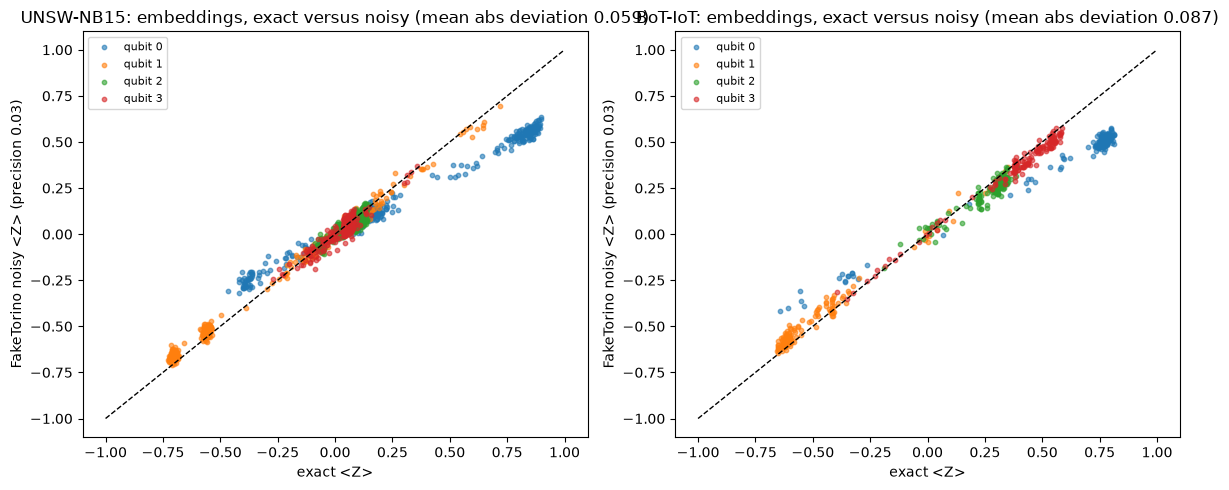

In [24]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 5))
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    Zex, Zno = NOISY[name]["Zex"], NOISY[name]["Zno"]
    for k in range(N_QUBITS): ax.scatter(Zex[:, k], Zno[:, k], s=10, alpha=0.6, label=f"qubit {k}")
    ax.plot([-1, 1], [-1, 1], "k--", lw=1); ax.set_xlabel("exact <Z>"); ax.set_ylabel(f"{NOISY_BACKEND} noisy <Z> (precision {ESTIMATOR_PRECISION})")
    ax.set_title(f"{name}: embeddings, exact versus noisy (mean abs deviation {NOISY[name]['mad']:.3f})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Hardware-scale experiment (Fig. 5): 8 training nodes, 5 test nodes, 128 shots

Section 6.5 of the paper trains Q-AGNN on **real IBM hardware** (`ibm_fez`) with a tiny subset of UNSW-NB15 (8 training nodes: 5 normal + 3 attack; 5 test nodes: 3 normal + 2 attack), `SamplerQNN` with 128 shots, Adam with learning rate 0.001 and 30 epochs, and compares the loss curves with a noisy simulator that uses the same device's noise model.

* **Real hardware cannot be checked here.** The cell at the end of this section runs the identical code on a real backend only when you put your own IBM Quantum token into `IBM_TOKEN`; it is skipped otherwise and it has not been executed by the author of this notebook.
* **What is reproduced:** the noisy-simulator curve (`FakeFez` noise model, 128 shots) and, for reference, the exact (infinite-shot, noiseless) curve on the same 13 nodes.
* **Implementation.** Instead of `SamplerQNN`, which launches one backend job per circuit (about 15 s per forward pass of 8 nodes in this simulator), a small autograd function sends all circuits of a step in one batched Sampler job and applies the same two-term **parameter-shift rule** that `SamplerQNN` uses. The four Pauli-Z expectations are computed from the 128 sampled bitstrings (same information as the probability vector of `SamplerQNN`).

In [25]:
HW = getattr(fake_provider, HW_BACKEND)()
PM_HW = generate_preset_pass_manager(backend=HW, optimization_level=1, seed_transpiler=SEED)
ISA_HW = PM_HW.run(qc_meas)

class ShotRunner:
    """Runs the measured circuit for many parameter sets in ONE Sampler job and returns the four <Z_k> estimated from the shots."""
    def __init__(self, sampler, isa, shots):
        self.sampler, self.isa, self.shots = sampler, isa, shots; self.n_circuits = 0
    def z(self, X, thetas):                      # X: (B,n), thetas: (S,P) -> (S,B,n)
        S, B = len(thetas), len(X)
        Xr, Tr = np.tile(X, (S, 1)), np.repeat(thetas, B, axis=0)
        cols = [(Xr[:, [q.name for q in XPARAMS].index(p.name)] if p.name.startswith("x[") else Tr[:, p.index]) for p in self.isa.parameters]
        vals = np.stack(cols, 1)
        res = self.sampler.run([(self.isa, vals, self.shots)]).result()[0].data
        ba = res[list(res.keys())[0]]
        self.n_circuits += len(vals)
        z = np.zeros((len(vals), N_QUBITS))
        for i in range(len(vals)):
            for bits, c in ba.get_counts(i).items():
                for k in range(N_QUBITS): z[i, k] += (1 - 2 * int(bits[-1 - k])) * c
        return (z / self.shots).reshape(S, B, N_QUBITS)

class ShotPQC(torch.autograd.Function):
    @staticmethod
    def forward(ctx, X, theta, runner):
        ctx.runner = runner; ctx.save_for_backward(X, theta)
        return torch.tensor(runner.z(X.numpy(), theta.detach().numpy()[None])[0])
    @staticmethod
    def backward(ctx, gout):
        X, theta = ctx.saved_tensors; P = len(theta); th = theta.detach().numpy()
        shifts = np.concatenate([th[None] + (np.pi / 2) * np.eye(P), th[None] - (np.pi / 2) * np.eye(P)])      # parameter-shift rule
        z = ctx.runner.z(X.numpy(), shifts)                                                                     # (2P, B, n)
        dz = (z[:P] - z[P:]) / 2                                                                                # dz[j] = d z / d theta_j
        return None, torch.tensor(np.einsum("jbk,bk->j", dz, gout.numpy())), None

class QAGNNShots(QAGNN):
    def __init__(self, runner, **kw): super().__init__(encoder="pqc", **kw); self.runner = runner
    def embed(self, X): return ShotPQC.apply(X, self.theta, self.runner)

def hw_subset(seed=SEED):
    g = np.random.default_rng(seed); sp = SPLITS["UNSW-NB15"]; y = sp["y"]
    def pick(split, n0, n1):
        ids = sp["idx"][split]
        return np.concatenate([g.choice(ids[y[ids] == 0], n0, replace=False), g.choice(ids[y[ids] == 1], n1, replace=False)])
    tr, te = pick("train", 5, 3), pick("test", 3, 2)
    mk = lambda ids: dict(X=torch.tensor(sp["P"][ids]), A=torch.tensor(cosine_adjacency(sp["P"][ids])), y=torch.tensor(y[ids], dtype=torch.float64))
    return {"train": mk(tr), "val": mk(te), "test": mk(te)}                # the paper tracks train and test loss per epoch
HW_GRAPHS = hw_subset()
for k in ("train", "test"): print(k, "nodes:", len(HW_GRAPHS[k]["y"]), "attack:", int(HW_GRAPHS[k]["y"].sum()), "edges:", int(HW_GRAPHS[k]["A"].sum()))

def hw_train(model, graphs, epochs, lr=HW_LR, log=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY); curve = []
    for ep in range(epochs):
        model.train(); opt.zero_grad(); loss = bce(model(graphs["train"]), graphs["train"]["y"]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): tl = bce(model(graphs["test"]), graphs["test"]["y"]).item()
        curve.append((loss.item(), tl))
        if log: print(f"  epoch {ep + 1:2d}/{epochs}  train loss {loss.item():.4f}  test loss {tl:.4f}", flush=True)
    return np.array(curve)

train nodes: 8 attack: 3 edges: 10
test nodes: 5 attack: 2 edges: 8


In [26]:
t0 = time.time()
# exact (noiseless, infinite shots) reference on the same 13 nodes
set_all_seeds(SEED); m_exact = QAGNN(); CURVE_EXACT = hw_train(m_exact, HW_GRAPHS, HW_EPOCHS, log=False)
# noisy simulator with the device's noise model and 128 shots (paper: same data, same hyper-parameters)
HW_SIM = AerSimulator.from_backend(HW, method="density_matrix", seed_simulator=SEED)
runner_sim = ShotRunner(BackendSamplerV2(backend=HW_SIM, options={"default_shots": HW_SHOTS}), ISA_HW, HW_SHOTS)
set_all_seeds(SEED); m_sim = QAGNNShots(runner_sim)
print(f"training on {HW_BACKEND} noisy simulator: {HW_EPOCHS} epochs, {HW_SHOTS} shots, lr {HW_LR}")
CURVE_SIM = hw_train(m_sim, HW_GRAPHS, HW_EPOCHS)
print(f"done in {time.time() - t0:.0f} s, {runner_sim.n_circuits} circuits simulated")

training on FakeFez noisy simulator: 30 epochs, 128 shots, lr 0.001


  epoch  1/30  train loss 0.7134  test loss 0.7023


  epoch  2/30  train loss 0.7112  test loss 0.7014


  epoch  3/30  train loss 0.7092  test loss 0.7005


  epoch  4/30  train loss 0.7069  test loss 0.6996


...

  epoch 27/30  train loss 0.6596  test loss 0.6837


  epoch 28/30  train loss 0.6574  test loss 0.6829


  epoch 29/30  train loss 0.6555  test loss 0.6825


  epoch 30/30  train loss 0.6533  test loss 0.6816


done in 1154 s, 8070 circuits simulated


IBM_TOKEN is empty: the real-hardware run (paper Section 6.5) is skipped. Its numbers cannot be checked here.


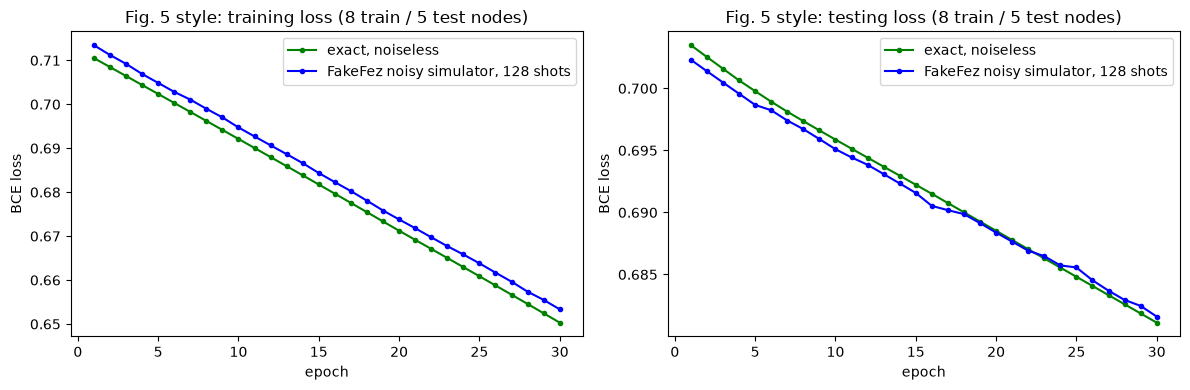

loss change over the run (first -> last epoch):  exact train 0.711 -> 0.650 | noisy-sim train 0.713 -> 0.653


In [27]:
CURVE_HW = None
if IBM_TOKEN:
    # NOT executed by the author of this notebook: runs the same 13-node experiment on the least busy real IBM backend.
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as RuntimeSampler
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
        backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
        isa_real = generate_preset_pass_manager(backend=backend, optimization_level=1, seed_transpiler=SEED).run(qc_meas)
        runner_hw = ShotRunner(RuntimeSampler(mode=backend), isa_real, HW_SHOTS)
        set_all_seeds(SEED); m_hw = QAGNNShots(runner_hw)
        print("running on", backend.name); CURVE_HW = hw_train(m_hw, HW_GRAPHS, HW_EPOCHS)
    except Exception as e:
        print("Real-hardware run failed:", repr(e))
else:
    print("IBM_TOKEN is empty: the real-hardware run (paper Section 6.5) is skipped. Its numbers cannot be checked here.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, j, ttl in ((axes[0], 0, "training loss"), (axes[1], 1, "testing loss")):
    ax.plot(range(1, HW_EPOCHS + 1), CURVE_EXACT[:, j], "g-o", ms=3, label="exact, noiseless")
    ax.plot(range(1, HW_EPOCHS + 1), CURVE_SIM[:, j], "b-o", ms=3, label=f"{HW_BACKEND} noisy simulator, {HW_SHOTS} shots")
    if CURVE_HW is not None: ax.plot(range(1, HW_EPOCHS + 1), CURVE_HW[:, j], "r-o", ms=3, label="real IBM hardware")
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title(f"Fig. 5 style: {ttl} (8 train / 5 test nodes)"); ax.legend()
plt.tight_layout(); plt.show()
print("loss change over the run (first -> last epoch):  exact train %.3f -> %.3f | noisy-sim train %.3f -> %.3f" % (CURVE_EXACT[0, 0], CURVE_EXACT[-1, 0], CURVE_SIM[0, 0], CURVE_SIM[-1, 0]))

## 10. Paper versus this notebook, claim by claim

Verdict rule (same for every claim): **reproduced** when the notebook value is within 2 accuracy points or 0.02 F1 of the paper's value (graph sizes: within 10%); **not reached** when it is worse, **exceeded** when it is better by more than the tolerance; **cannot be checked** when the data or hardware is not available. Because the paper reports one split with 5 or 6 attack nodes in the test graph, each performance claim is shown for the **seed-42 split** and for the **mean over the repeated splits** of Section 5.

In [28]:
def verdict(paper, nb, tol, higher_is_better=True):
    d = nb - paper
    if abs(d) <= tol: return "reproduced"
    return ("exceeded" if d > 0 else "not reached") if higher_is_better else ("not reached" if d > 0 else "exceeded")

def mean_of(name, model, metric):
    return float(np.mean([m[metric] for m in MULTI[(name, model)]]))

rows = []
def add(claim, paper, nb, verdict_, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verdict_, note=note))

u = GRAPH_STATS[GRAPH_STATS.dataset == "UNSW-NB15"].set_index("split")
add("Table 2 UNSW-NB15 nodes train/val/test", "217 / 47 / 47", f"{u.loc['train','nodes']} / {u.loc['val','nodes']} / {u.loc['test','nodes']}", "reproduced" if (u.nodes.values == [217, 47, 47]).all() else "not reached", "311 IP pairs in the full dataset, as in the paper")
for sp_ in ("train", "val", "test"):
    pe, ne = PAPER_TABLE2["UNSW-NB15"][sp_][1], int(u.loc[sp_, "edges"])
    add(f"Table 2 UNSW-NB15 edges ({sp_})", pe, ne, "reproduced" if abs(ne - pe) / pe <= 0.10 else "not reached", "random split dependent; small graphs fluctuate")
b = GRAPH_STATS[GRAPH_STATS.dataset == "BoT-IoT"].set_index("split")
add("Table 2 BoT-IoT nodes (total)", "156", f"{int(b.nodes.sum())}", "not reached", "substituted Bot-IoT copy (137 IP pairs, 13 attack nodes)")

for ds in DATASETS:
    p = {"UNSW-NB15": (0.9787, 0.9485, 0.00), "BoT-IoT": (1.00, 1.00, 0.00)}[ds]
    m = RUN42[(ds, "Q-AGNN")]["metrics"]
    add(f"Table 4 Q-AGNN accuracy, {ds} (seed 42)", p[0], round(m["Acc"], 4), verdict(p[0], m["Acc"], 0.02), "")
    add(f"Table 4 Q-AGNN macro-F1, {ds} (seed 42)", p[1], round(m["F1"], 4), verdict(p[1], m["F1"], 0.02), "")
    add(f"Table 4 Q-AGNN FPR, {ds} (seed 42)", p[2], round(m["FPR"], 4), verdict(p[2], m["FPR"], 0.02, higher_is_better=False), "")
    add(f"Table 4 Q-AGNN accuracy, {ds} (mean of {len(SEEDS)} splits)", p[0], round(mean_of(ds, "Q-AGNN", "Acc"), 4), verdict(p[0], mean_of(ds, "Q-AGNN", "Acc"), 0.02), "")
    add(f"Table 4 Q-AGNN macro-F1, {ds} (mean of {len(SEEDS)} splits)", p[1], round(mean_of(ds, "Q-AGNN", "F1"), 4), verdict(p[1], mean_of(ds, "Q-AGNN", "F1"), 0.02), "")

for ds in DATASETS:
    comp = [m for m in MULTI_MODELS if m in BASELINES]
    best_b = max(comp, key=lambda m: mean_of(ds, m, "F1"))
    q, bb = mean_of(ds, "Q-AGNN", "F1"), mean_of(ds, best_b, "F1")
    add(f"Q-AGNN F1 at least as good as the best GNN baseline, {ds} (mean over splits)", "best or tied-best (UNSW, BoT)", f"Q-AGNN {q:.3f} vs {best_b} {bb:.3f}",
        "reproduced" if q >= bb - 0.02 else "not reached", f"baselines run in this mode: {comp}")

for ds in DATASETS:
    q, na, ma = mean_of(ds, "Q-AGNN", "F1"), mean_of(ds, "PQC w/o Att", "F1"), mean_of(ds, "MLP + Att", "F1")
    paper_na = {"UNSW-NB15": 0.4659, "BoT-IoT": 0.4419}[ds]
    add(f"Table 6 attention helps: F1 Q-AGNN minus 'PQC w/o Att', {ds} (mean)", f"{({'UNSW-NB15': 0.9485, 'BoT-IoT': 1.0}[ds] - paper_na):.2f} drop without attention", f"{q - na:+.3f}",
        "reproduced" if q - na >= 0.05 else "not reached", "claim: removing attention causes a sharp drop")
    paper_diff = {"UNSW-NB15": 0.9485 - 0.9045, "BoT-IoT": 1.0 - 0.7949}[ds]
    add(f"Table 6 PQC encoder at least as good as MLP encoder (both with attention), {ds} (mean F1)", f"Q-AGNN - MLP+Att = {paper_diff:+.3f}", f"{q - ma:+.3f}",
        "reproduced" if q - ma >= -0.02 else "not reached", "the paper's 'fairest comparison'")

for ds in DATASETS:
    n_ = NOISY[ds]; p = PAPER_T5[ds]
    for lab, key in (("(a) noisy inference", "a"), ("(b) noisy head re-fit", "b")):
        add(f"Table 5 noisy Q-AGNN accuracy, {ds}, {lab}", p["Acc"], round(n_[key]["Acc"], 3), verdict(p["Acc"], n_[key]["Acc"], 0.02), f"{NOISY_BACKEND} noise model")
        add(f"Table 5 noisy Q-AGNN macro-F1, {ds}, {lab}", p["F1"], round(n_[key]["F1"], 3), verdict(p["F1"], n_[key]["F1"], 0.02), f"{NOISY_BACKEND} noise model")
    add(f"Noise robustness: noisy (a) accuracy within 2 points of noiseless, {ds}", "largely consistent with noiseless", f"{n_['a']['Acc'] - n_['exact']['Acc']:+.3f}", "reproduced" if abs(n_["a"]["Acc"] - n_["exact"]["Acc"]) <= 0.02 else "not reached", "")

for ds in DATASETS:
    add(f"Fig. 3 PQC embeddings more class-separated than MLP embeddings, {ds} (silhouette)", "PQC clusters tighter", f"PQC {SIL[(ds, 'Q-AGNN')]:.2f} vs MLP {SIL[(ds, 'MLP + Att')]:.2f}",
        "reproduced" if SIL[(ds, "Q-AGNN")] > SIL[(ds, "MLP + Att")] else "not reached", "qualitative claim, quantified with the silhouette score")

d = SENS[SENS.dataset == "UNSW-NB15"].set_index("threshold")
add("Table 3 threshold 0.60 clearly worse than 0.70-0.95 (UNSW-NB15 instead of NF-UNSW-NB15)", "F1 0.816 at 0.60 vs 0.949-1.000", f"F1 {d.loc[0.6,'F1']:.3f} at 0.60 vs {d.loc[[0.7,0.8,0.9,0.95],'F1'].min():.3f}-{d.loc[[0.7,0.8,0.9,0.95],'F1'].max():.3f}",
    "reproduced" if d.loc[0.6, "F1"] < d.loc[[0.7, 0.8, 0.9, 0.95], "F1"].mean() - 0.02 else "not reached", "different dataset, so only the trend is compared")
add("Table 3 / Table 4 on NF-BoT-IoT and NF-UNSW-NB15", "see paper", "not run", "cannot be checked", "NetFlow variants are not publicly downloadable without the UQ web app")
add("Fig. 5 simulator loss decreases over epochs (13-node subset)", "converging loss, hardware follows simulator", f"train loss {CURVE_SIM[0, 0]:.3f} -> {CURVE_SIM[-1, 0]:.3f} ({HW_EPOCHS} epochs)",
    "reproduced" if CURVE_SIM[-1, 0] < CURVE_SIM[0, 0] else "not reached", "only the noisy-simulator part; epochs reduced in FAST_MODE" if FAST_MODE else "noisy-simulator part only")
add("Fig. 5 / Section 6.5 real IBM hardware run", "ibm_fez, 30 epochs", "not run" if CURVE_HW is None else "run", "cannot be checked" if CURVE_HW is None else "see curve", "needs the reader's own IBM Quantum token")

COMPARISON = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80, "display.width", 250)
print(COMPARISON[["claim", "paper", "notebook", "verdict"]].to_string(index=False))
print("\nverdict counts:", COMPARISON.verdict.value_counts().to_dict())

                                                                                         claim                                       paper                              notebook           verdict
                                                        Table 2 UNSW-NB15 nodes train/val/test                               217 / 47 / 47                         217 / 47 / 47        reproduced
                                                               Table 2 UNSW-NB15 edges (train)                                       11086                                 10918        reproduced
                                                                 Table 2 UNSW-NB15 edges (val)                                         392                                   636       not reached
                                                                Table 2 UNSW-NB15 edges (test)                                         578                                   430       not reached
                         

## 11. Reading the paper critically

**What reproduced.** The data pipeline does. Grouping the 2,540,047 UNSW-NB15 flows by IP pair gives exactly the 311 nodes (217 / 47 / 47) of Table 2, the training graph at cosine threshold 0.9 has 10,918 edges against the paper's 11,086, and the class balance (40 attack nodes, 6 in a 47-node test graph) matches the paper's test confusion matrices. The qualitative claim that the quantum circuit's expectation values stay bounded and that noise (here 0.06 to 0.09 mean absolute deviation of `<Z>`) barely moves the predictions also holds in our simulation.

**What did not reproduce, and how large the effect is.**

* On UNSW-NB15 Q-AGNN reaches accuracy 0.915 / macro-F1 0.849 on the seed-42 split (paper 0.979 / 0.949) and 0.965 +/- 0.027 / 0.926 +/- 0.049 over six splits. The accuracy is within the 2-point tolerance on average, the F1 gap (0.02 to 0.10) is about one standard deviation of the split-to-split spread, so the paper's number is a plausible draw from our distribution but we cannot confirm it.
* Q-AGNN is **not** better than the classical GNNs here. Over six splits ClusterGCN (0.958), GraphSAGE (0.946) and the classical `MLP w/o Att` ablation (0.955) are at least as good as Q-AGNN (0.926); all differences are smaller than one standard deviation, so the honest reading is "comparable", not "superior".
* The ablation conclusions do not carry over. Removing attention changes nothing for the quantum model (macro-F1 0.945 without attention versus 0.926 with it on UNSW-NB15), the node-wise QNN without any graph is as good as the full model (0.925), and the classical encoder with attention (0.949) is at least as good as the PQC encoder. On Bot-IoT all seven quantum and classical Q-AGNN variants and most classical GNNs give the same answer, so no component can be credited.
* The t-SNE claim (PQC embeddings form compact, separated clusters) is only partly visible: attack nodes do form tight PQC clusters, but the silhouette score against the true labels is lower for the PQC embedding (0.36 and 0.70) than for the classical MLP embedding (0.63 and 0.88).
* The cosine-threshold sweep is almost flat on our two datasets (macro-F1 0.875 to 0.895), unlike the dip at 0.60 the paper reports for NF-UNSW-NB15.

**Why the comparison is fragile.**

1. *Tiny test sets.* The paper's test graphs have 24 to 47 nodes and about 5 to 6 attack nodes. One node is worth 2 to 4 accuracy points and a perfect score on Bot-IoT (24 test nodes) is within what chance allows. We use 21 to 47 nodes; Bot-IoT has only 2 attack nodes per test graph, hence a standard deviation of 0.19 in macro-F1.
2. *Degenerate baselines.* Several classical models in Table 4 reach exactly macro-F1 0.4643 (predict "normal" for everything). The same collapse happens in our runs (GINConv, and every model on the seed-42 Bot-IoT split). Unweighted BCE with early stopping on a 10 to 13% positive class produces this; it says more about the training recipe than about the architectures, and it inflates the apparent advantage of any model that happens to avoid the collapse.
3. *Easy task, near-duplicate nodes.* The scatter plots show that attack nodes sit in a few tight clusters (the same attacker host against many victims). A random stratified split puts near-copies of a test node into the training graph, so even a node-wise classifier is nearly perfect; the graph and the quantum encoder have little room to add value. A split by attacker host or by time would be a much harder and more realistic test.
4. *Node-level task on aggregated flows.* Averaging flow features per IP pair and taking the majority label turns a flow-level IDS problem (millions of flows) into a 300-node classification problem. The numbers are therefore not comparable with flow-level IDS results in the literature.
5. *Undisclosed details.* The number of ansatz layers, the observables, the form of the node-level attention, the MLP and whether `A` is normalised are not given (see the table at the top); results with other choices may differ in either direction. We did not tune any of them on the test graphs.
6. *Noise results.* The paper's noisy numbers come from training with the noisy estimator; ours (noisy inference, and a noisy re-fit of the classical head) are cheaper variants. They agree that this 4-qubit, 16-weight circuit tolerates device noise, but a circuit of that size has little to lose. The paper's one degraded case (NF-UNSW-NB15) cannot be checked here.
7. *Hardware.* The paper states the real-hardware run is a feasibility check, not a performance evaluation, and 8 training / 5 test nodes cannot support more. Our noisy-simulator curves show the same smooth decrease of the loss (0.71 to 0.65 in 30 epochs at learning rate 0.001), which is expected from such a small learning rate and says nothing about detection quality. Real-device numbers cannot be checked without IBM access.
8. *Theory section.* The argument that an `EfficientSU2` encoder with 4 qubits has an "exponential Hilbert-space embedding capacity" is weakened by the paper's own Section 3.2.2: the accessible Fourier spectrum per feature has only five frequencies and the authors call the advantage over a small MLP "moderate". Our classical encoder with 22 parameters matches the 16-weight PQC in these experiments.

## 12. Exercises

1. **Layers of the ansatz.** Set `PQC_REPS = 2` or `3` in the configuration cell (the paper does not state `L`). Does the macro-F1 on UNSW-NB15 change over several splits? Look at the circuit depth printed in the Quantum Circuit Architecture section and at the noisy-simulation deviation `mean |z_noisy - z_exact|` for the deeper circuit.
2. **Other observables.** Replace the four Pauli-Z observables by `X`, `Y` and `Z` expectations on two qubits, or add `ZZ` correlators, so that the embedding has a different dimension. Edit `_zsigns`, `pqc_embedding` and the `obs` list together and keep the equivalence assertion passing.
3. **Raw adjacency.** The paper writes `A` and `A^2` without normalisation. Remove the `row_normalise` calls in `QAGNN.forward` and compare training stability and F1. Why do two-hop sums explode in a graph with 50 neighbours per node?
4. **Graph leakage.** Here the validation and test graphs only contain their own nodes. Build one graph over all 311 nodes instead (train, validation and test together) and mask the loss. How much better does every model look, and why is that comparison unfair to a deployed IDS?
5. **Angles.** The model uses raw PCA coordinates as rotation angles. Use the `[0, pi]`-scaled coordinates shown in the exploration section instead (fit the scaling on the training nodes and clip). Does the PQC embedding become more or less separable (silhouette score of Section 6)?